In [1]:
# ============================================================
# SMARTVISION AI - CLASSIFICATION TRAINING
# Phase 1: Preprocessing & Augmentation
# Phase 2: Transfer Learning
# ============================================================

import os
import random
import numpy as np
import torch
import torchvision

from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Dataset paths
# ------------------------------------------------------------

BASE_DIR = Path(r"E:\SmartVision-AI\data\final_dataset")

CLASSIFICATION_DIR = BASE_DIR / "classification"

TRAIN_DIR = CLASSIFICATION_DIR / "train"
VAL_DIR   = CLASSIFICATION_DIR / "val"
TEST_DIR  = CLASSIFICATION_DIR / "test"

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

NUM_CLASSES = 25
IMAGE_SIZE = 224
BATCH_SIZE = 32

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("SMARTVISION AI - CLASSIFICATION SETUP")
print("=" * 70)

print("PyTorch version     :", torch.__version__)
print("Torchvision version :", torchvision.__version__)

print("\nDataset:")
print("Train exists :", TRAIN_DIR.exists())
print("Val exists   :", VAL_DIR.exists())
print("Test exists  :", TEST_DIR.exists())

print("\nConfiguration:")
print("Classes    :", NUM_CLASSES)
print("Image size :", IMAGE_SIZE)
print("Batch size :", BATCH_SIZE)

print("\nHardware:")
print("Device     :", device)

if torch.cuda.is_available():
    print("GPU        :", torch.cuda.get_device_name(0))
    print(
        "GPU memory :",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )

print("=" * 70)

SMARTVISION AI - CLASSIFICATION SETUP
PyTorch version     : 2.11.0+cu128
Torchvision version : 0.26.0+cu128

Dataset:
Train exists : True
Val exists   : True
Test exists  : True

Configuration:
Classes    : 25
Image size : 224
Batch size : 32

Hardware:
Device     : cuda
GPU        : NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory : 6.0 GB


In [2]:
# ============================================================
# CELL 2: PREPROCESSING AND DATA AUGMENTATION
# ============================================================

# ImageNet normalization values
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


# ------------------------------------------------------------
# TRAINING TRANSFORMS
# Includes required data augmentation
# ------------------------------------------------------------

train_transform = transforms.Compose([

    # Ensure standard input size
    transforms.Resize((224, 224)),

    # Horizontal flip
    transforms.RandomHorizontalFlip(p=0.5),

    # Rotation ±15 degrees
    transforms.RandomRotation(degrees=15),

    # Random zoom
    transforms.RandomAffine(
        degrees=0,
        scale=(0.90, 1.10)
    ),

    # Brightness ±20%, contrast adjustment + color jitter
    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.20,
        hue=0.05
    ),

    # Convert PIL image to tensor
    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ------------------------------------------------------------
# VALIDATION / TEST TRANSFORMS
# No random augmentation
# ------------------------------------------------------------

eval_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


print("=" * 70)
print("IMAGE PREPROCESSING & AUGMENTATION")
print("=" * 70)

print("\nTRAINING TRANSFORMS:")
print(train_transform)

print("\nVALIDATION / TEST TRANSFORMS:")
print(eval_transform)

print("\nRequired augmentation:")
print("Horizontal flip     : ✅")
print("Rotation ±15°       : ✅")
print("Brightness ±20%     : ✅")
print("Contrast adjustment : ✅")
print("Random zoom         : ✅")
print("Color jitter        : ✅")
print("ImageNet normalize  : ✅")

print("=" * 70)


IMAGE PREPROCESSING & AUGMENTATION

TRAINING TRANSFORMS:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    RandomAffine(degrees=[0.0, 0.0], scale=(0.9, 1.1))
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

VALIDATION / TEST TRANSFORMS:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Required augmentation:
Horizontal flip     : ✅
Rotation ±15°       : ✅
Brightness ±20%     : ✅
Contrast adjustment : ✅
Random zoom         : ✅
Color jitter        : ✅
ImageNet normalize  : ✅


In [3]:
# ============================================================
# CELL 3: CREATE PYTORCH IMAGEFOLDER DATASETS
# ============================================================

# Create datasets
train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)


# ------------------------------------------------------------
# Dataset information
# ------------------------------------------------------------

print("=" * 70)
print("PYTORCH DATASET VERIFICATION")
print("=" * 70)

print("\nDataset sizes:")
print(f"Train : {len(train_dataset)}")
print(f"Val   : {len(val_dataset)}")
print(f"Test  : {len(test_dataset)}")
print(f"Total : {len(train_dataset) + len(val_dataset) + len(test_dataset)}")

print("\nNumber of classes:")
print("Train :", len(train_dataset.classes))
print("Val   :", len(val_dataset.classes))
print("Test  :", len(test_dataset.classes))

print("\nClass mapping:")
for class_name, class_idx in train_dataset.class_to_idx.items():
    print(f"{class_idx:2d} -> {class_name}")


# ------------------------------------------------------------
# Verify class mappings are identical
# ------------------------------------------------------------

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

# Verify expected counts
assert len(train_dataset) == 1750
assert len(val_dataset) == 375
assert len(test_dataset) == 375

assert len(train_dataset.classes) == 25

print("\n" + "=" * 70)
print("✅ Train / validation / test class mappings are identical.")
print("✅ Dataset sizes are correct.")
print("✅ 25 classes detected successfully.")
print("=" * 70)

PYTORCH DATASET VERIFICATION

Dataset sizes:
Train : 1750
Val   : 375
Test  : 375
Total : 2500

Number of classes:
Train : 25
Val   : 25
Test  : 25

Class mapping:
 0 -> airplane
 1 -> bed
 2 -> bench
 3 -> bicycle
 4 -> bird
 5 -> bottle
 6 -> bowl
 7 -> bus
 8 -> cake
 9 -> car
10 -> cat
11 -> chair
12 -> cow
13 -> cup
14 -> dog
15 -> elephant
16 -> horse
17 -> motorcycle
18 -> person
19 -> pizza
20 -> potted plant
21 -> stop sign
22 -> traffic light
23 -> train
24 -> truck

✅ Train / validation / test class mappings are identical.
✅ Dataset sizes are correct.
✅ 25 classes detected successfully.


In [4]:
# ============================================================
# CELL 4: CREATE DATALOADERS
# ============================================================

# Windows/Jupyter friendly setting
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# ------------------------------------------------------------
# Load one training batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("=" * 70)
print("DATALOADER VERIFICATION")
print("=" * 70)

print("\nNumber of batches:")
print("Train :", len(train_loader))
print("Val   :", len(val_loader))
print("Test  :", len(test_loader))

print("\nFirst training batch:")
print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)
print("Image dtype       :", images.dtype)
print("Label dtype       :", labels.dtype)

print("\nPixel range after normalization:")
print(f"Minimum : {images.min().item():.4f}")
print(f"Maximum : {images.max().item():.4f}")

print("\nFirst 10 labels:")
print(labels[:10].tolist())

print("\nCorresponding classes:")
print([train_dataset.classes[i] for i in labels[:10].tolist()])

print("\n" + "=" * 70)
print("✅ DataLoaders created successfully.")
print("=" * 70)

DATALOADER VERIFICATION

Number of batches:
Train : 55
Val   : 12
Test  : 12

First training batch:
Image batch shape : torch.Size([32, 3, 224, 224])
Label batch shape : torch.Size([32])
Image dtype       : torch.float32
Label dtype       : torch.int64

Pixel range after normalization:
Minimum : -2.1179
Maximum : 2.6400

First 10 labels:
[19, 20, 6, 15, 24, 22, 7, 20, 16, 5]

Corresponding classes:
['pizza', 'potted plant', 'bowl', 'elephant', 'truck', 'traffic light', 'bus', 'potted plant', 'horse', 'bottle']

✅ DataLoaders created successfully.


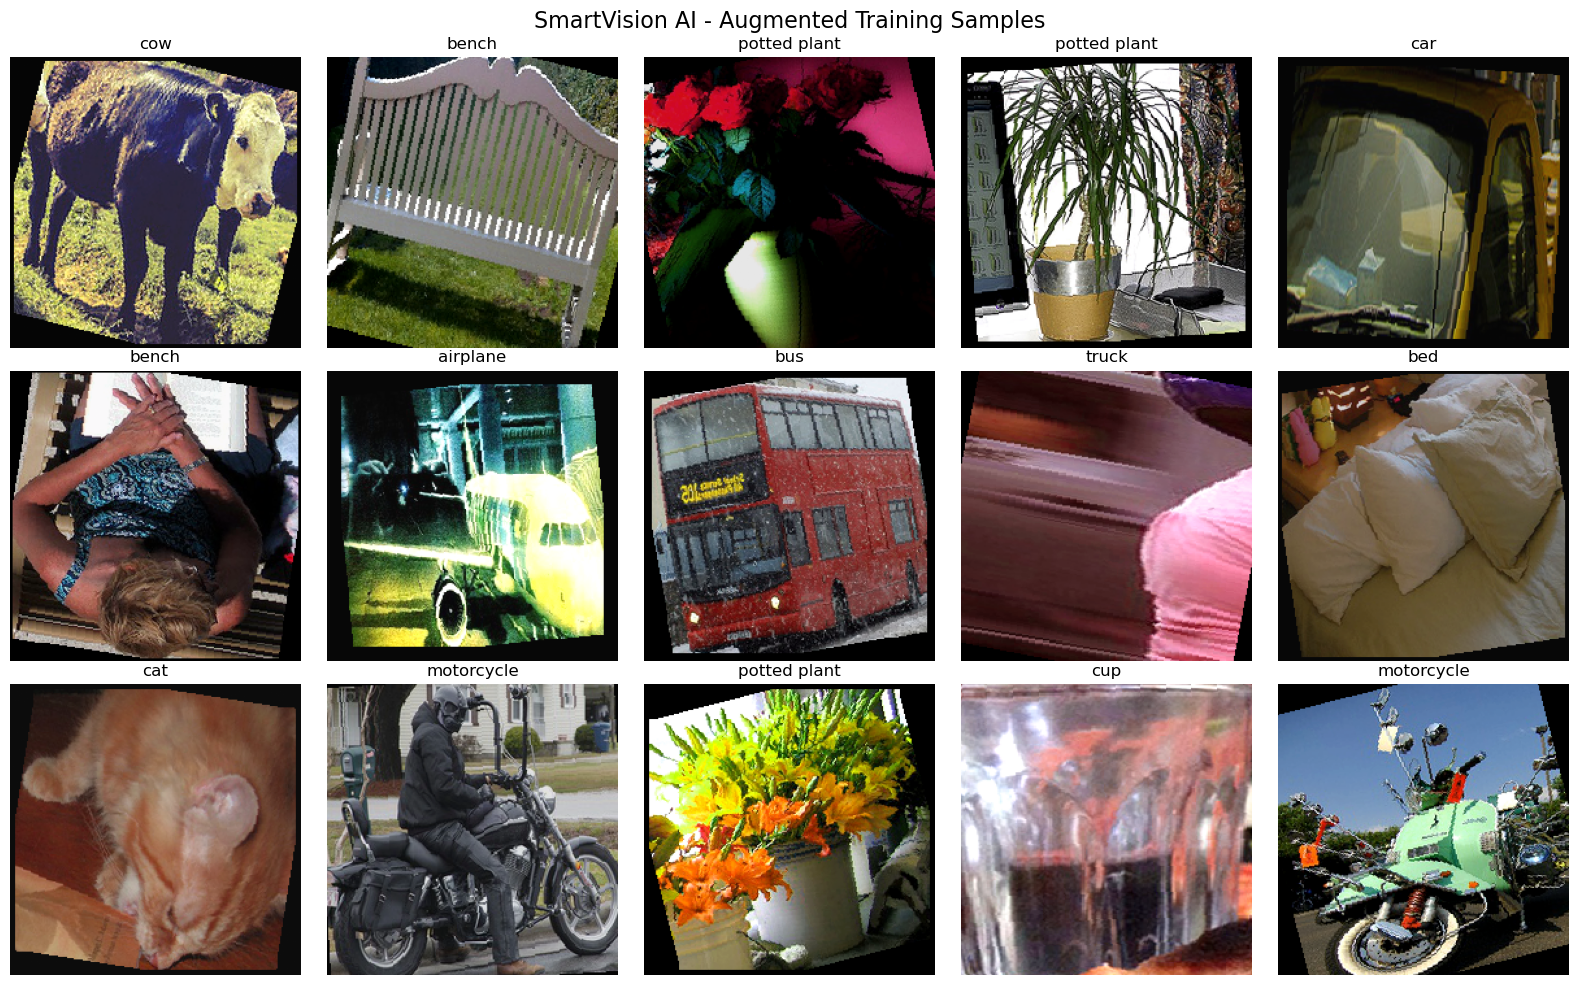

In [6]:
# ============================================================
# CELL 5: VISUALIZE AUGMENTED TRAINING IMAGES
# ============================================================

import matplotlib.pyplot as plt

# ImageNet values as tensors for reversing normalization
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)


def denormalize(image):
    """
    Reverse ImageNet normalization for visualization.
    """
    image = image.cpu() * std + mean
    return torch.clamp(image, 0, 1)


# Get a fresh batch so random augmentation is applied
images, labels = next(iter(train_loader))

plt.figure(figsize=(16, 10))

for i in range(15):

    image = denormalize(images[i])

    # CHW -> HWC for matplotlib
    image = image.permute(1, 2, 0).numpy()

    plt.subplot(3, 5, i + 1)
    plt.imshow(image)

    class_name = train_dataset.classes[labels[i].item()]
    plt.title(class_name)

    plt.axis("off")

plt.suptitle(
    "SmartVision AI - Augmented Training Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

## PHASE - 2

In [7]:
# ============================================================
# PHASE 2 - CELL 1
# VERIFY FINAL CLASSIFICATION TRAINING ENVIRONMENT
# ============================================================

import torch

print("=" * 72)
print("PHASE 2 - CLASSIFICATION TRAINING")
print("=" * 72)

required_objects = [
    "train_loader",
    "val_loader",
    "test_loader",
    "train_dataset",
    "val_dataset",
    "test_dataset"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    print("❌ Missing objects:")
    for name in missing:
        print("  -", name)

    print("\nRerun the preprocessing/DataLoader cells above first.")

else:
    print("✅ DataLoaders ready")

    print("\nDataset:")
    print("Train :", len(train_dataset))
    print("Val   :", len(val_dataset))
    print("Test  :", len(test_dataset))
    print("Total :", (
        len(train_dataset)
        + len(val_dataset)
        + len(test_dataset)
    ))

    print("\nClasses :", len(train_dataset.classes))

    print("\nHardware:")
    print("PyTorch :", torch.__version__)
    print("CUDA    :", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU     :", torch.cuda.get_device_name(0))

print("=" * 72)

PHASE 2 - CLASSIFICATION TRAINING
✅ DataLoaders ready

Dataset:
Train : 1750
Val   : 375
Test  : 375
Total : 2500

Classes : 25

Hardware:
PyTorch : 2.11.0+cu128
CUDA    : True
GPU     : NVIDIA GeForce RTX 4050 Laptop GPU


In [8]:
# ============================================================
# PHASE 2 - CELL 2
# BUILD VGG16 MODEL
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_CLASSES = 25

print("=" * 72)
print("BUILDING VGG16")
print("=" * 72)

# ------------------------------------------------------------
# 1. Load ImageNet pretrained VGG16
# ------------------------------------------------------------

weights = models.VGG16_Weights.IMAGENET1K_V1

vgg16 = models.vgg16(weights=weights)

# ------------------------------------------------------------
# 2. Freeze convolutional base
# ------------------------------------------------------------

for param in vgg16.features.parameters():
    param.requires_grad = False

# ------------------------------------------------------------
# 3. Replace original classifier with custom head
# ------------------------------------------------------------

vgg16.classifier = nn.Sequential(

    nn.Linear(25088, 1024),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.5),

    nn.Linear(1024, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.3),

    nn.Linear(256, NUM_CLASSES)
)

# ------------------------------------------------------------
# 4. Move model to GPU
# ------------------------------------------------------------

vgg16 = vgg16.to(device)

# ------------------------------------------------------------
# 5. Parameter statistics
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in vgg16.parameters()
)

trainable_params = sum(
    p.numel()
    for p in vgg16.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print("Device           :", device)
print("Output classes   :", NUM_CLASSES)

print("\nParameters:")
print(f"Total            : {total_params:,}")
print(f"Trainable        : {trainable_params:,}")
print(f"Frozen           : {frozen_params:,}")

# ------------------------------------------------------------
# 6. Verify convolutional base is frozen
# ------------------------------------------------------------

features_frozen = all(
    not p.requires_grad
    for p in vgg16.features.parameters()
)

print("\nConvolutional base frozen:", features_frozen)

print("\nClassifier:")
print(vgg16.classifier)

print("\n" + "=" * 72)
print("✅ VGG16 MODEL READY")
print("=" * 72)


BUILDING VGG16
Device           : cuda
Output classes   : 25

Parameters:
Total            : 40,674,649
Trainable        : 25,959,961
Frozen           : 14,714,688

Convolutional base frozen: True

Classifier:
Sequential(
  (0): Linear(in_features=25088, out_features=1024, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=1024, out_features=256, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=256, out_features=25, bias=True)
)

✅ VGG16 MODEL READY


In [9]:
# ============================================================
# PHASE 2 - CELL 3
# VGG16 TRAINING CONFIGURATION
# ============================================================

import torch.optim as optim
from pathlib import Path

# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

VGG_EPOCHS = 20
VGG_LEARNING_RATE = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        vgg16.parameters()
    ),
    lr=VGG_LEARNING_RATE
)

# Reduce LR when validation loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# Model output folder
# ------------------------------------------------------------

MODEL_DIR = Path(r"E:\SmartVision-AI\models")
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

VGG_BEST_PATH = MODEL_DIR / "vgg16_final_best.pth"

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

vgg_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": []
}

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 72)
print("VGG16 TRAINING CONFIGURATION")
print("=" * 72)

print("Epochs          :", VGG_EPOCHS)
print("Learning rate   :", VGG_LEARNING_RATE)
print("Loss            : CrossEntropyLoss")
print("Optimizer       : Adam")
print("LR scheduler    : ReduceLROnPlateau")
print("Scheduler factor: 0.5")
print("Scheduler patience:", 2)

print("\nBest model path:")
print(VGG_BEST_PATH)

print("\nTrain batches :", len(train_loader))
print("Val batches   :", len(val_loader))

print("\n" + "=" * 72)
print("✅ VGG16 training configuration ready.")
print("=" * 72)

VGG16 TRAINING CONFIGURATION
Epochs          : 20
Learning rate   : 0.0001
Loss            : CrossEntropyLoss
Optimizer       : Adam
LR scheduler    : ReduceLROnPlateau
Scheduler factor: 0.5
Scheduler patience: 2

Best model path:
E:\SmartVision-AI\models\vgg16_final_best.pth

Train batches : 55
Val batches   : 12

✅ VGG16 training configuration ready.


In [10]:
# ============================================================
# PHASE 2 - CELL 4
# TRAIN VGG16
# ============================================================

import time
import copy

best_val_acc = 0.0
best_epoch = 0

print("=" * 72)
print("VGG16 TRAINING STARTED")
print("=" * 72)

training_start = time.time()

for epoch in range(VGG_EPOCHS):

    epoch_start = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    vgg16.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = vgg16(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ========================================================
    # VALIDATION
    # ========================================================

    vgg16.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = vgg16(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ========================================================
    # LEARNING RATE SCHEDULER
    # ========================================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    vgg_history["train_loss"].append(train_loss)
    vgg_history["train_acc"].append(train_acc)

    vgg_history["val_loss"].append(val_loss)
    vgg_history["val_acc"].append(val_acc)

    vgg_history["lr"].append(current_lr)


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    saved = ""

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": vgg16.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": best_val_acc,
                "class_names": train_dataset.classes
            },
            VGG_BEST_PATH
        )

        saved = "  ⭐ BEST MODEL SAVED"


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch+1:02d}/{VGG_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:6.2f}% | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
        f"{saved}"
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

total_time = time.time() - training_start

print("\n" + "=" * 72)
print("VGG16 TRAINING COMPLETE")
print("=" * 72)

print(f"Best epoch              : {best_epoch}")
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
print(f"Total training time     : {total_time/60:.2f} minutes")

print("\nBest model saved at:")
print(VGG_BEST_PATH)

print("=" * 72)

VGG16 TRAINING STARTED
Epoch [01/20] | Train Loss: 2.4681 | Train Acc:  31.83% | Val Loss: 1.2135 | Val Acc:  72.80% | LR: 1.00e-04 | Time: 40.7s  ⭐ BEST MODEL SAVED
Epoch [02/20] | Train Loss: 1.3153 | Train Acc:  64.06% | Val Loss: 0.8298 | Val Acc:  77.60% | LR: 1.00e-04 | Time: 27.1s  ⭐ BEST MODEL SAVED
Epoch [03/20] | Train Loss: 0.9577 | Train Acc:  71.66% | Val Loss: 0.6421 | Val Acc:  81.60% | LR: 1.00e-04 | Time: 27.1s  ⭐ BEST MODEL SAVED
Epoch [04/20] | Train Loss: 0.7572 | Train Acc:  78.34% | Val Loss: 0.6113 | Val Acc:  82.13% | LR: 1.00e-04 | Time: 27.2s  ⭐ BEST MODEL SAVED
Epoch [05/20] | Train Loss: 0.6051 | Train Acc:  81.03% | Val Loss: 0.6249 | Val Acc:  80.53% | LR: 1.00e-04 | Time: 26.4s
Epoch [06/20] | Train Loss: 0.5198 | Train Acc:  83.66% | Val Loss: 0.5801 | Val Acc:  82.67% | LR: 1.00e-04 | Time: 26.8s  ⭐ BEST MODEL SAVED
Epoch [07/20] | Train Loss: 0.4041 | Train Acc:  88.06% | Val Loss: 0.5806 | Val Acc:  82.13% | LR: 1.00e-04 | Time: 26.4s
Epoch [08/20] | 

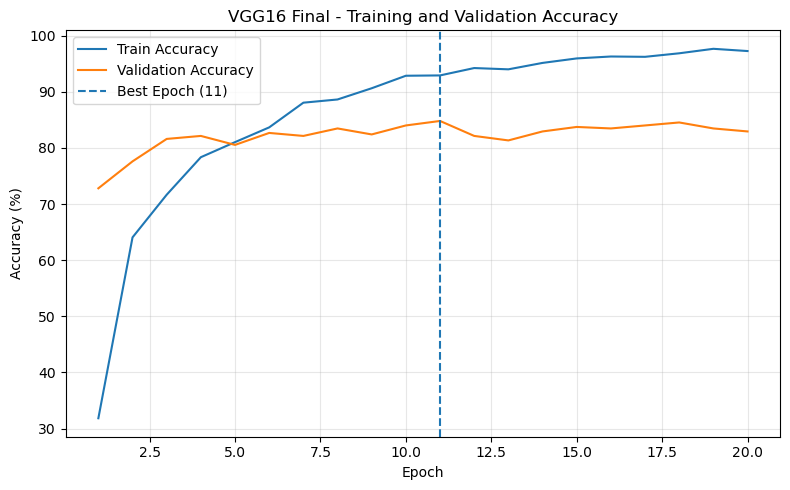

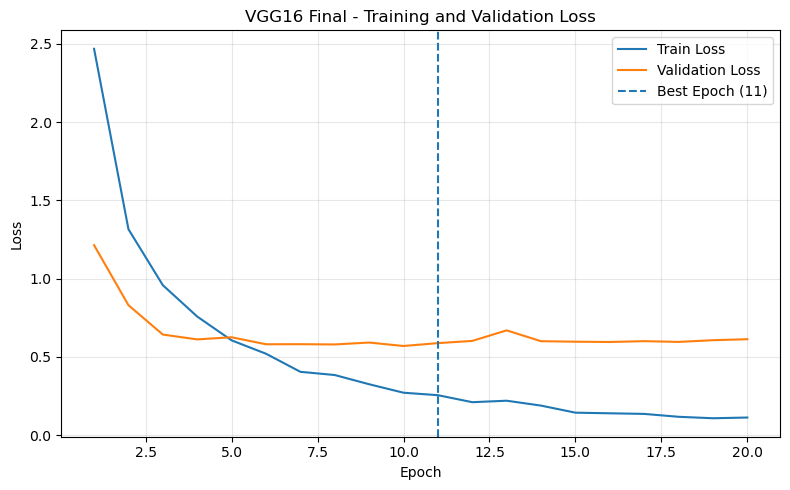

VGG16 FINAL TRAINING ARTIFACTS SAVED
History : E:\SmartVision-AI\results\classification\vgg16_final_history.json
Accuracy: E:\SmartVision-AI\results\classification\vgg16_final_accuracy_curve.png
Loss    : E:\SmartVision-AI\results\classification\vgg16_final_loss_curve.png

Best epoch       : 11
Best Val Accuracy: 84.80%


In [11]:
# ============================================================
# PHASE 2 - CELL 5
# SAVE VGG16 HISTORY + TRAINING CURVES
# ============================================================

import json
import matplotlib.pyplot as plt

RESULTS_DIR = Path(r"E:\SmartVision-AI\results\classification")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

VGG_HISTORY_PATH = RESULTS_DIR / "vgg16_final_history.json"
VGG_CURVE_PATH = RESULTS_DIR / "vgg16_final_training_curves.png"

# ------------------------------------------------------------
# Save training history
# ------------------------------------------------------------

history_to_save = {
    "train_loss": [float(x) for x in vgg_history["train_loss"]],
    "train_acc": [float(x) for x in vgg_history["train_acc"]],
    "val_loss": [float(x) for x in vgg_history["val_loss"]],
    "val_acc": [float(x) for x in vgg_history["val_acc"]],
    "lr": [float(x) for x in vgg_history["lr"]],
    "best_epoch": int(best_epoch),
    "best_val_accuracy": float(best_val_acc)
}

with open(VGG_HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(history_to_save, f, indent=4)


# ------------------------------------------------------------
# Plot accuracy
# ------------------------------------------------------------

epochs = range(1, len(vgg_history["train_acc"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [x * 100 for x in vgg_history["train_acc"]],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in vgg_history["val_acc"]],
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("VGG16 Final - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vgg16_final_accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Plot loss
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    vgg_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    vgg_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Final - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vgg16_final_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("=" * 72)
print("VGG16 FINAL TRAINING ARTIFACTS SAVED")
print("=" * 72)

print("History :", VGG_HISTORY_PATH)
print("Accuracy:",
      RESULTS_DIR / "vgg16_final_accuracy_curve.png")
print("Loss    :",
      RESULTS_DIR / "vgg16_final_loss_curve.png")

print("\nBest epoch       :", best_epoch)
print(f"Best Val Accuracy: {best_val_acc * 100:.2f}%")

print("=" * 72)

In [12]:
# ============================================================
# PHASE 2 - CELL 6
# BUILD FINAL RESNET50
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 25

print("=" * 72)
print("BUILDING RESNET50")
print("=" * 72)

# ------------------------------------------------------------
# 1. Load ImageNet pretrained ResNet50
# ------------------------------------------------------------

weights = models.ResNet50_Weights.IMAGENET1K_V2

resnet50 = models.resnet50(weights=weights)

# ------------------------------------------------------------
# 2. Freeze entire pretrained network first
# ------------------------------------------------------------

for param in resnet50.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# 3. Unfreeze last 20 parameterized layers
# ------------------------------------------------------------
# We count modules that directly own trainable parameters
# (Conv2d, BatchNorm2d, Linear), rather than individual tensors.

parameterized_layers = [
    module
    for module in resnet50.modules()
    if isinstance(
        module,
        (nn.Conv2d, nn.BatchNorm2d, nn.Linear)
    )
]

# Exclude original ImageNet FC because it will be replaced
backbone_layers = parameterized_layers[:-1]

for layer in backbone_layers[-20:]:
    for param in layer.parameters():
        param.requires_grad = True


# ------------------------------------------------------------
# 4. Replace ImageNet classification layer
# ------------------------------------------------------------

in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(

    nn.Linear(in_features, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.4),

    nn.Linear(512, NUM_CLASSES)
)


# ------------------------------------------------------------
# 5. Move model to GPU
# ------------------------------------------------------------

resnet50 = resnet50.to(device)


# ------------------------------------------------------------
# 6. Parameter statistics
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in resnet50.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet50.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params


print("Device         :", device)
print("Output classes :", NUM_CLASSES)

print("\nFine-tuning:")
print("Total parameterized backbone layers :", len(backbone_layers))
print("Unfrozen final backbone layers       :", 20)

print("\nParameters:")
print(f"Total      : {total_params:,}")
print(f"Trainable  : {trainable_params:,}")
print(f"Frozen     : {frozen_params:,}")

print("\nClassification head:")
print(resnet50.fc)

print("\n" + "=" * 72)
print("✅ RESNET50 MODEL READY")
print("=" * 72)

BUILDING RESNET50
Device         : cuda
Output classes : 25

Fine-tuning:
Total parameterized backbone layers : 106
Unfrozen final backbone layers       : 20

Parameters:
Total      : 24,569,945
Trainable  : 16,026,649
Frozen     : 8,543,296

Classification head:
Sequential(
  (0): Linear(in_features=2048, out_features=512, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=512, out_features=25, bias=True)
)

✅ RESNET50 MODEL READY


In [13]:
# ============================================================
# PHASE 2 - CELL 7
# RESNET50 FINAL TRAINING CONFIGURATION
# ============================================================

import torch.optim as optim
from pathlib import Path

# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

RESNET_EPOCHS = 25
RESNET_LEARNING_RATE = 1e-4
RESNET_EARLY_STOPPING_PATIENCE = 5

criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet50.parameters()
    ),
    lr=RESNET_LEARNING_RATE
)

# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler_resnet = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_resnet,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# Final model path
# ------------------------------------------------------------

MODEL_DIR = Path(r"E:\SmartVision-AI\models")
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESNET_BEST_PATH = MODEL_DIR / "resnet50_final_best.pth"

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

resnet_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": []
}

# ------------------------------------------------------------
# Early stopping variables
# ------------------------------------------------------------

resnet_best_val_loss = float("inf")
resnet_best_val_acc = 0.0
resnet_best_epoch = 0
resnet_no_improvement = 0

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 72)
print("RESNET50 FINAL TRAINING CONFIGURATION")
print("=" * 72)

print("Maximum epochs        :", RESNET_EPOCHS)
print("Learning rate         :", RESNET_LEARNING_RATE)
print("Loss                  : CrossEntropyLoss")
print("Optimizer             : Adam")

print("\nLR Scheduler:")
print("Type                  : ReduceLROnPlateau")
print("Factor                : 0.5")
print("Patience              : 2")

print("\nEarly Stopping:")
print("Monitor               : Validation Loss")
print("Patience              :", RESNET_EARLY_STOPPING_PATIENCE)

print("\nBest model path:")
print(RESNET_BEST_PATH)

print("\nTrain batches :", len(train_loader))
print("Val batches   :", len(val_loader))

print("\n" + "=" * 72)
print("✅ RESNET50 FINAL TRAINING CONFIGURATION READY")
print("=" * 72)

RESNET50 FINAL TRAINING CONFIGURATION
Maximum epochs        : 25
Learning rate         : 0.0001
Loss                  : CrossEntropyLoss
Optimizer             : Adam

LR Scheduler:
Type                  : ReduceLROnPlateau
Factor                : 0.5
Patience              : 2

Early Stopping:
Monitor               : Validation Loss
Patience              : 5

Best model path:
E:\SmartVision-AI\models\resnet50_final_best.pth

Train batches : 55
Val batches   : 12

✅ RESNET50 FINAL TRAINING CONFIGURATION READY


In [14]:
# ============================================================
# PHASE 2 - CELL 8
# TRAIN FINAL RESNET50 WITH EARLY STOPPING
# ============================================================

import time

print("=" * 72)
print("RESNET50 FINAL TRAINING STARTED")
print("=" * 72)

training_start = time.time()

for epoch in range(RESNET_EPOCHS):

    epoch_start = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    resnet50.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_resnet.zero_grad()

        outputs = resnet50(images)

        loss = criterion_resnet(outputs, labels)

        loss.backward()
        optimizer_resnet.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ========================================================
    # VALIDATION
    # ========================================================

    resnet50.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = resnet50(images)

            loss = criterion_resnet(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ========================================================
    # LEARNING-RATE SCHEDULER
    # ========================================================

    scheduler_resnet.step(val_loss)

    current_lr = optimizer_resnet.param_groups[0]["lr"]


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    resnet_history["train_loss"].append(train_loss)
    resnet_history["train_acc"].append(train_acc)

    resnet_history["val_loss"].append(val_loss)
    resnet_history["val_acc"].append(val_acc)

    resnet_history["lr"].append(current_lr)


    # ========================================================
    # CHECKPOINT + EARLY STOPPING
    # ========================================================

    saved = ""

    # Improvement is based on validation loss because
    # early stopping also monitors validation loss.
    if val_loss < resnet_best_val_loss:

        resnet_best_val_loss = val_loss
        resnet_best_val_acc = val_acc
        resnet_best_epoch = epoch + 1

        resnet_no_improvement = 0

        torch.save(
            {
                "epoch": resnet_best_epoch,
                "model_state_dict": resnet50.state_dict(),
                "optimizer_state_dict":
                    optimizer_resnet.state_dict(),
                "val_loss": resnet_best_val_loss,
                "val_accuracy": resnet_best_val_acc,
                "class_names": train_dataset.classes
            },
            RESNET_BEST_PATH
        )

        saved = "  ⭐ BEST MODEL SAVED"

    else:

        resnet_no_improvement += 1


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch+1:02d}/{RESNET_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:6.2f}% | "
        f"LR: {current_lr:.2e} | "
        f"No Improve: "
        f"{resnet_no_improvement}/"
        f"{RESNET_EARLY_STOPPING_PATIENCE} | "
        f"Time: {epoch_time:.1f}s"
        f"{saved}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        resnet_no_improvement
        >= RESNET_EARLY_STOPPING_PATIENCE
    ):

        print("\n" + "-" * 72)
        print(
            f"⏹ Early stopping triggered at "
            f"epoch {epoch + 1}."
        )

        print(
            f"Best validation loss: "
            f"{resnet_best_val_loss:.4f}"
        )

        print(
            f"Best checkpoint epoch: "
            f"{resnet_best_epoch}"
        )

        print("-" * 72)

        break


# ============================================================
# FINAL SUMMARY
# ============================================================

total_time = time.time() - training_start

print("\n" + "=" * 72)
print("RESNET50 FINAL TRAINING COMPLETE")
print("=" * 72)

print(
    f"Best checkpoint epoch   : "
    f"{resnet_best_epoch}"
)

print(
    f"Best validation loss    : "
    f"{resnet_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at "
    f"best checkpoint: "
    f"{resnet_best_val_acc*100:.2f}%"
)

print(
    f"Total training time     : "
    f"{total_time/60:.2f} minutes"
)

print("\nBest model saved at:")
print(RESNET_BEST_PATH)

print("=" * 72)

RESNET50 FINAL TRAINING STARTED
Epoch [01/25] | Train Loss: 2.7047 | Train Acc:  39.94% | Val Loss: 1.4321 | Val Acc:  74.93% | LR: 1.00e-04 | No Improve: 0/5 | Time: 23.5s  ⭐ BEST MODEL SAVED
Epoch [02/25] | Train Loss: 1.0320 | Train Acc:  76.00% | Val Loss: 0.5077 | Val Acc:  86.13% | LR: 1.00e-04 | No Improve: 0/5 | Time: 22.9s  ⭐ BEST MODEL SAVED
Epoch [03/25] | Train Loss: 0.5129 | Train Acc:  86.34% | Val Loss: 0.3945 | Val Acc:  90.40% | LR: 1.00e-04 | No Improve: 0/5 | Time: 23.0s  ⭐ BEST MODEL SAVED
Epoch [04/25] | Train Loss: 0.3554 | Train Acc:  89.89% | Val Loss: 0.4058 | Val Acc:  88.53% | LR: 1.00e-04 | No Improve: 1/5 | Time: 22.7s
Epoch [05/25] | Train Loss: 0.2509 | Train Acc:  93.03% | Val Loss: 0.4224 | Val Acc:  89.07% | LR: 1.00e-04 | No Improve: 2/5 | Time: 22.6s
Epoch [06/25] | Train Loss: 0.1737 | Train Acc:  95.43% | Val Loss: 0.4095 | Val Acc:  89.07% | LR: 5.00e-05 | No Improve: 3/5 | Time: 22.5s
Epoch [07/25] | Train Loss: 0.1264 | Train Acc:  96.34% | Val 

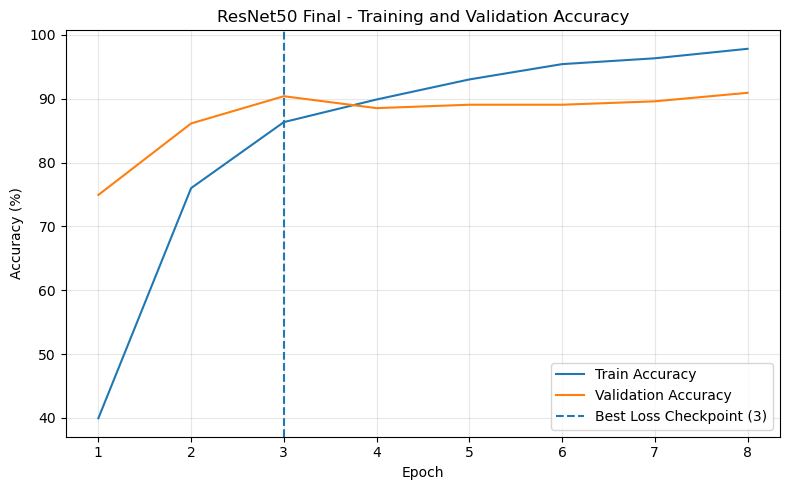

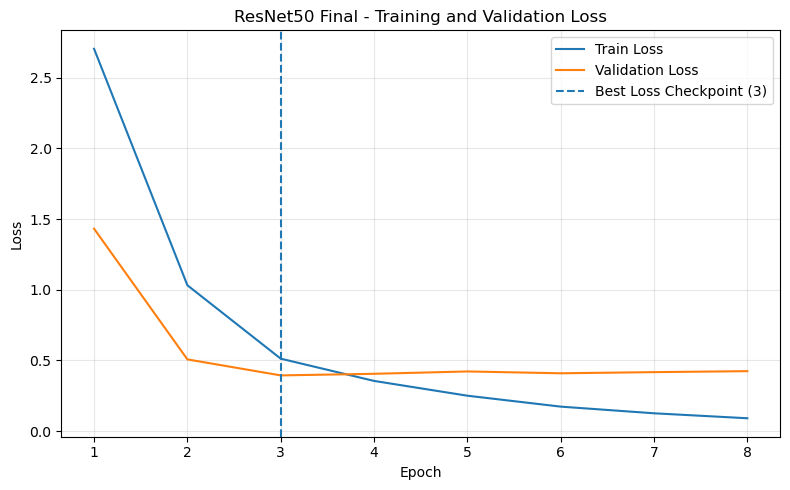

RESNET50 FINAL TRAINING ARTIFACTS SAVED
History : E:\SmartVision-AI\results\classification\resnet50_final_history.json
Accuracy: E:\SmartVision-AI\results\classification\resnet50_final_accuracy_curve.png
Loss    : E:\SmartVision-AI\results\classification\resnet50_final_loss_curve.png

Checkpoint selected by validation loss:
Epoch              : 3
Validation loss    : 0.3945
Validation accuracy: 90.40%

Highest validation accuracy observed:
Epoch              : 8
Validation accuracy: 90.93%

Early stopping epoch: 8


In [15]:
# ============================================================
# PHASE 2 - CELL 9
# SAVE RESNET50 FINAL HISTORY + TRAINING CURVES
# ============================================================

import json
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(r"E:\SmartVision-AI\results\classification")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RESNET_HISTORY_PATH = (
    RESULTS_DIR / "resnet50_final_history.json"
)

RESNET_ACCURACY_PATH = (
    RESULTS_DIR / "resnet50_final_accuracy_curve.png"
)

RESNET_LOSS_PATH = (
    RESULTS_DIR / "resnet50_final_loss_curve.png"
)

# Highest validation accuracy observed during training
resnet_peak_val_acc = max(resnet_history["val_acc"])

resnet_peak_val_epoch = (
    resnet_history["val_acc"].index(resnet_peak_val_acc) + 1
)

# ------------------------------------------------------------
# Save history
# ------------------------------------------------------------

history_to_save = {
    "train_loss": [
        float(x) for x in resnet_history["train_loss"]
    ],
    "train_acc": [
        float(x) for x in resnet_history["train_acc"]
    ],
    "val_loss": [
        float(x) for x in resnet_history["val_loss"]
    ],
    "val_acc": [
        float(x) for x in resnet_history["val_acc"]
    ],
    "lr": [
        float(x) for x in resnet_history["lr"]
    ],

    "checkpoint_epoch": int(resnet_best_epoch),

    "checkpoint_val_loss":
        float(resnet_best_val_loss),

    "checkpoint_val_accuracy":
        float(resnet_best_val_acc),

    "peak_val_accuracy":
        float(resnet_peak_val_acc),

    "peak_val_accuracy_epoch":
        int(resnet_peak_val_epoch)
}

with open(
    RESNET_HISTORY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        history_to_save,
        f,
        indent=4
    )


# ------------------------------------------------------------
# Accuracy curve
# ------------------------------------------------------------

epochs = range(
    1,
    len(resnet_history["train_acc"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [x * 100 for x in resnet_history["train_acc"]],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in resnet_history["val_acc"]],
    label="Validation Accuracy"
)

plt.axvline(
    resnet_best_epoch,
    linestyle="--",
    label=f"Best Loss Checkpoint ({resnet_best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "ResNet50 Final - Training and Validation Accuracy"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESNET_ACCURACY_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Loss curve
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    resnet_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    resnet_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    resnet_best_epoch,
    linestyle="--",
    label=f"Best Loss Checkpoint ({resnet_best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 Final - Training and Validation Loss"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESNET_LOSS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("=" * 72)
print("RESNET50 FINAL TRAINING ARTIFACTS SAVED")
print("=" * 72)

print("History :", RESNET_HISTORY_PATH)
print("Accuracy:", RESNET_ACCURACY_PATH)
print("Loss    :", RESNET_LOSS_PATH)

print("\nCheckpoint selected by validation loss:")
print("Epoch              :", resnet_best_epoch)
print(
    f"Validation loss    : "
    f"{resnet_best_val_loss:.4f}"
)
print(
    f"Validation accuracy: "
    f"{resnet_best_val_acc * 100:.2f}%"
)

print("\nHighest validation accuracy observed:")
print(
    f"Epoch              : "
    f"{resnet_peak_val_epoch}"
)
print(
    f"Validation accuracy: "
    f"{resnet_peak_val_acc * 100:.2f}%"
)

print("\nEarly stopping epoch:",
      len(resnet_history["train_loss"]))

print("=" * 72)

In [16]:
# ============================================================
# PHASE 2 - CELL 10
# BUILD FINAL MOBILENETV2
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 25

print("=" * 72)
print("BUILDING MOBILENETV2")
print("=" * 72)

# ------------------------------------------------------------
# 1. Load ImageNet pretrained MobileNetV2
# ------------------------------------------------------------

weights = models.MobileNet_V2_Weights.IMAGENET1K_V1

mobilenetv2 = models.mobilenet_v2(
    weights=weights
)

# ------------------------------------------------------------
# 2. Freeze pretrained feature extractor
# ------------------------------------------------------------

for param in mobilenetv2.features.parameters():
    param.requires_grad = False

# ------------------------------------------------------------
# 3. Replace classification head
# ------------------------------------------------------------

in_features = mobilenetv2.classifier[1].in_features

mobilenetv2.classifier = nn.Sequential(

    nn.Dropout(p=0.3),

    nn.Linear(
        in_features,
        512
    ),

    nn.ReLU(inplace=True),

    nn.Dropout(p=0.3),

    nn.Linear(
        512,
        NUM_CLASSES
    )
)

# ------------------------------------------------------------
# 4. Move to GPU
# ------------------------------------------------------------

mobilenetv2 = mobilenetv2.to(device)

# ------------------------------------------------------------
# 5. Parameter statistics
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in mobilenetv2.parameters()
)

trainable_params = sum(
    p.numel()
    for p in mobilenetv2.parameters()
    if p.requires_grad
)

frozen_params = (
    total_params - trainable_params
)

features_frozen = all(
    not p.requires_grad
    for p in mobilenetv2.features.parameters()
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("Device                  :", device)
print("Output classes          :", NUM_CLASSES)

print("\nTransfer Learning:")
print(
    "Feature extractor frozen:",
    features_frozen
)

print("\nParameters:")
print(f"Total      : {total_params:,}")
print(f"Trainable  : {trainable_params:,}")
print(f"Frozen     : {frozen_params:,}")

print("\nClassification head:")
print(mobilenetv2.classifier)

print("\n" + "=" * 72)
print("✅ MOBILENETV2 MODEL READY")
print("=" * 72)

BUILDING MOBILENETV2
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\athiy/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


100%|█████████████████████████████████████████████████████████████████████████████| 13.6M/13.6M [00:03<00:00, 3.95MB/s]

Device                  : cuda
Output classes          : 25

Transfer Learning:
Feature extractor frozen: True

Parameters:
Total      : 2,892,569
Trainable  : 668,697
Frozen     : 2,223,872

Classification head:
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=512, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=512, out_features=25, bias=True)
)

✅ MOBILENETV2 MODEL READY


In [17]:
# ============================================================
# PHASE 2 - CELL 11
# MOBILENETV2 FINAL TRAINING CONFIGURATION
# ============================================================

import torch.optim as optim
from pathlib import Path

# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

MOBILE_EPOCHS = 20
MOBILE_LEARNING_RATE = 1e-4

criterion_mobile = nn.CrossEntropyLoss()

optimizer_mobile = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        mobilenetv2.parameters()
    ),
    lr=MOBILE_LEARNING_RATE
)

# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler_mobile = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mobile,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# Final model path
# ------------------------------------------------------------

MODEL_DIR = Path(r"E:\SmartVision-AI\models")
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MOBILE_BEST_PATH = (
    MODEL_DIR / "mobilenetv2_final_best.pth"
)

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

mobile_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": []
}

mobile_best_val_acc = 0.0
mobile_best_epoch = 0

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 72)
print("MOBILENETV2 FINAL TRAINING CONFIGURATION")
print("=" * 72)

print("Epochs            :", MOBILE_EPOCHS)
print("Learning rate     :", MOBILE_LEARNING_RATE)
print("Loss              : CrossEntropyLoss")
print("Optimizer         : Adam")

print("\nLR Scheduler:")
print("Type              : ReduceLROnPlateau")
print("Monitor           : Validation Loss")
print("Factor            : 0.5")
print("Patience          : 2")

print("\nCheckpoint:")
print("Monitor           : Validation Accuracy")
print("Best model path   :")
print(MOBILE_BEST_PATH)

print("\nTrain batches :", len(train_loader))
print("Val batches   :", len(val_loader))

print("\n" + "=" * 72)
print("✅ MOBILENETV2 FINAL TRAINING CONFIGURATION READY")
print("=" * 72)

MOBILENETV2 FINAL TRAINING CONFIGURATION
Epochs            : 20
Learning rate     : 0.0001
Loss              : CrossEntropyLoss
Optimizer         : Adam

LR Scheduler:
Type              : ReduceLROnPlateau
Monitor           : Validation Loss
Factor            : 0.5
Patience          : 2

Checkpoint:
Monitor           : Validation Accuracy
Best model path   :
E:\SmartVision-AI\models\mobilenetv2_final_best.pth

Train batches : 55
Val batches   : 12

✅ MOBILENETV2 FINAL TRAINING CONFIGURATION READY


In [18]:
# ============================================================
# PHASE 2 - CELL 12
# TRAIN FINAL MOBILENETV2
# ============================================================

import time

print("=" * 72)
print("MOBILENETV2 FINAL TRAINING STARTED")
print("=" * 72)

training_start = time.time()

for epoch in range(MOBILE_EPOCHS):

    epoch_start = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    mobilenetv2.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_mobile.zero_grad()

        outputs = mobilenetv2(images)

        loss = criterion_mobile(outputs, labels)

        loss.backward()
        optimizer_mobile.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (
            predicted == labels
        ).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ========================================================
    # VALIDATION
    # ========================================================

    mobilenetv2.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = mobilenetv2(images)

            loss = criterion_mobile(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ========================================================
    # LR SCHEDULER
    # ========================================================

    scheduler_mobile.step(val_loss)

    current_lr = optimizer_mobile.param_groups[0]["lr"]


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    mobile_history["train_loss"].append(train_loss)
    mobile_history["train_acc"].append(train_acc)

    mobile_history["val_loss"].append(val_loss)
    mobile_history["val_acc"].append(val_acc)

    mobile_history["lr"].append(current_lr)


    # ========================================================
    # SAVE BEST CHECKPOINT
    # ========================================================

    saved = ""

    if val_acc > mobile_best_val_acc:

        mobile_best_val_acc = val_acc
        mobile_best_epoch = epoch + 1

        torch.save(
            {
                "epoch": mobile_best_epoch,
                "model_state_dict":
                    mobilenetv2.state_dict(),

                "optimizer_state_dict":
                    optimizer_mobile.state_dict(),

                "val_accuracy":
                    mobile_best_val_acc,

                "class_names":
                    train_dataset.classes
            },
            MOBILE_BEST_PATH
        )

        saved = "  ⭐ BEST MODEL SAVED"


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch+1:02d}/{MOBILE_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:6.2f}% | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
        f"{saved}"
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

total_time = time.time() - training_start

print("\n" + "=" * 72)
print("MOBILENETV2 FINAL TRAINING COMPLETE")
print("=" * 72)

print(
    f"Best epoch              : "
    f"{mobile_best_epoch}"
)

print(
    f"Best validation accuracy: "
    f"{mobile_best_val_acc*100:.2f}%"
)

print(
    f"Total training time     : "
    f"{total_time/60:.2f} minutes"
)

print("\nBest model saved at:")
print(MOBILE_BEST_PATH)

print("=" * 72)

MOBILENETV2 FINAL TRAINING STARTED
Epoch [01/20] | Train Loss: 3.0843 | Train Acc:  16.06% | Val Loss: 2.7544 | Val Acc:  49.33% | LR: 1.00e-04 | Time: 21.2s  ⭐ BEST MODEL SAVED
Epoch [02/20] | Train Loss: 2.6152 | Train Acc:  40.91% | Val Loss: 2.1865 | Val Acc:  66.67% | LR: 1.00e-04 | Time: 20.9s  ⭐ BEST MODEL SAVED
Epoch [03/20] | Train Loss: 2.1244 | Train Acc:  54.29% | Val Loss: 1.7220 | Val Acc:  69.60% | LR: 1.00e-04 | Time: 20.8s  ⭐ BEST MODEL SAVED
Epoch [04/20] | Train Loss: 1.7599 | Train Acc:  61.94% | Val Loss: 1.4269 | Val Acc:  72.53% | LR: 1.00e-04 | Time: 21.0s  ⭐ BEST MODEL SAVED
Epoch [05/20] | Train Loss: 1.5121 | Train Acc:  64.86% | Val Loss: 1.2085 | Val Acc:  77.87% | LR: 1.00e-04 | Time: 21.0s  ⭐ BEST MODEL SAVED
Epoch [06/20] | Train Loss: 1.3487 | Train Acc:  68.11% | Val Loss: 1.0709 | Val Acc:  76.80% | LR: 1.00e-04 | Time: 20.9s
Epoch [07/20] | Train Loss: 1.2095 | Train Acc:  69.89% | Val Loss: 0.9818 | Val Acc:  78.13% | LR: 1.00e-04 | Time: 21.0s  ⭐ B

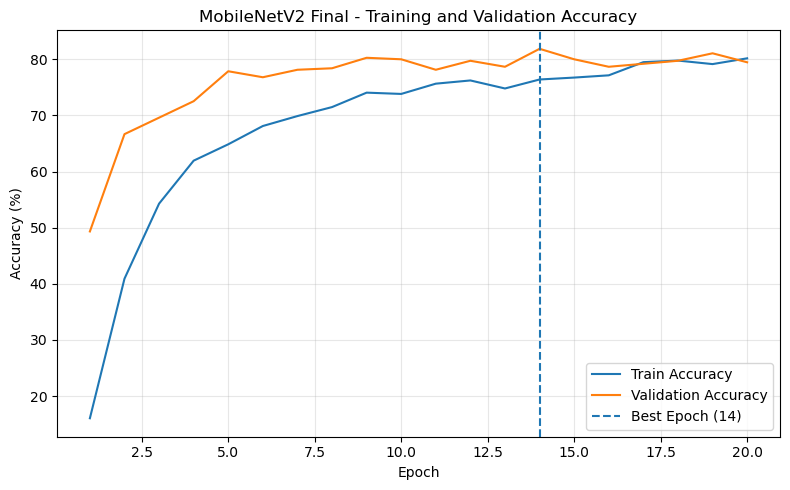

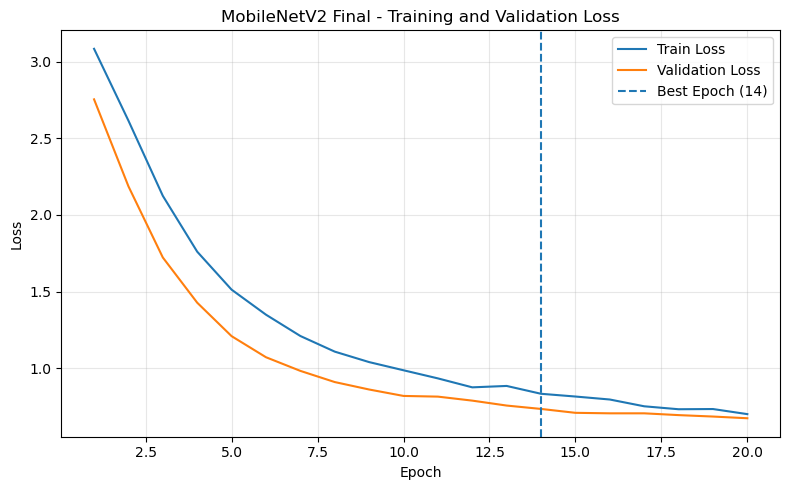

MOBILENETV2 FINAL TRAINING ARTIFACTS SAVED
History : E:\SmartVision-AI\results\classification\mobilenetv2_final_history.json
Accuracy: E:\SmartVision-AI\results\classification\mobilenetv2_final_accuracy_curve.png
Loss    : E:\SmartVision-AI\results\classification\mobilenetv2_final_loss_curve.png

Best epoch       : 14
Best Val Accuracy: 81.87%


In [19]:
# ============================================================
# PHASE 2 - CELL 13
# SAVE MOBILENETV2 FINAL HISTORY + TRAINING CURVES
# ============================================================

import json
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(r"E:\SmartVision-AI\results\classification")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MOBILE_HISTORY_PATH = (
    RESULTS_DIR / "mobilenetv2_final_history.json"
)

MOBILE_ACCURACY_PATH = (
    RESULTS_DIR / "mobilenetv2_final_accuracy_curve.png"
)

MOBILE_LOSS_PATH = (
    RESULTS_DIR / "mobilenetv2_final_loss_curve.png"
)

# ------------------------------------------------------------
# Save history
# ------------------------------------------------------------

history_to_save = {
    "train_loss": [
        float(x) for x in mobile_history["train_loss"]
    ],
    "train_acc": [
        float(x) for x in mobile_history["train_acc"]
    ],
    "val_loss": [
        float(x) for x in mobile_history["val_loss"]
    ],
    "val_acc": [
        float(x) for x in mobile_history["val_acc"]
    ],
    "lr": [
        float(x) for x in mobile_history["lr"]
    ],
    "best_epoch": int(mobile_best_epoch),
    "best_val_accuracy": float(mobile_best_val_acc)
}

with open(
    MOBILE_HISTORY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        history_to_save,
        f,
        indent=4
    )


# ------------------------------------------------------------
# Accuracy curve
# ------------------------------------------------------------

epochs = range(
    1,
    len(mobile_history["train_acc"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [x * 100 for x in mobile_history["train_acc"]],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in mobile_history["val_acc"]],
    label="Validation Accuracy"
)

plt.axvline(
    mobile_best_epoch,
    linestyle="--",
    label=f"Best Epoch ({mobile_best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "MobileNetV2 Final - Training and Validation Accuracy"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    MOBILE_ACCURACY_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Loss curve
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    mobile_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    mobile_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    mobile_best_epoch,
    linestyle="--",
    label=f"Best Epoch ({mobile_best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "MobileNetV2 Final - Training and Validation Loss"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    MOBILE_LOSS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("=" * 72)
print("MOBILENETV2 FINAL TRAINING ARTIFACTS SAVED")
print("=" * 72)

print("History :", MOBILE_HISTORY_PATH)
print("Accuracy:", MOBILE_ACCURACY_PATH)
print("Loss    :", MOBILE_LOSS_PATH)

print("\nBest epoch       :", mobile_best_epoch)

print(
    f"Best Val Accuracy: "
    f"{mobile_best_val_acc * 100:.2f}%"
)

print("=" * 72)

In [20]:
# ============================================================
# PHASE 2 - CELL 14
# BUILD FINAL EFFICIENTNETB0
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 25

print("=" * 72)
print("BUILDING EFFICIENTNETB0")
print("=" * 72)

# ------------------------------------------------------------
# 1. Load ImageNet pretrained EfficientNetB0
# ------------------------------------------------------------

weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1

efficientnetb0 = models.efficientnet_b0(
    weights=weights
)

# ------------------------------------------------------------
# 2. Freeze complete feature extractor initially
# ------------------------------------------------------------

for param in efficientnetb0.features.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# 3. Fine-tune final EfficientNet feature blocks
# ------------------------------------------------------------
# EfficientNet-B0 features contains sequential stages.
# We unfreeze the final two stages for controlled fine-tuning.

for param in efficientnetb0.features[-2:].parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# 4. Replace classifier with custom head
#    including Batch Normalization
# ------------------------------------------------------------

in_features = efficientnetb0.classifier[1].in_features

efficientnetb0.classifier = nn.Sequential(

    nn.Dropout(p=0.4),

    nn.Linear(
        in_features,
        512
    ),

    nn.BatchNorm1d(512),

    nn.SiLU(),

    nn.Dropout(p=0.3),

    nn.Linear(
        512,
        NUM_CLASSES
    )
)


# ------------------------------------------------------------
# 5. Move model to GPU
# ------------------------------------------------------------

efficientnetb0 = efficientnetb0.to(device)


# ------------------------------------------------------------
# 6. Parameter statistics
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in efficientnetb0.parameters()
)

trainable_params = sum(
    p.numel()
    for p in efficientnetb0.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

# Check final two feature stages
final_stages_trainable = all(
    p.requires_grad
    for p in efficientnetb0.features[-2:].parameters()
)


# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("Device                  :", device)
print("Output classes          :", NUM_CLASSES)

print("\nFine-tuning:")
print("Feature stages          :", len(efficientnetb0.features))
print("Final stages unfrozen   : 2")
print(
    "Final stages trainable  :",
    final_stages_trainable
)

print("\nParameters:")
print(f"Total      : {total_params:,}")
print(f"Trainable  : {trainable_params:,}")
print(f"Frozen     : {frozen_params:,}")

print("\nClassification head:")
print(efficientnetb0.classifier)

print("\n" + "=" * 72)
print("✅ EFFICIENTNETB0 MODEL READY")
print("=" * 72)

BUILDING EFFICIENTNETB0
Device                  : cuda
Output classes          : 25

Fine-tuning:
Feature stages          : 9
Final stages unfrozen   : 2
Final stages trainable  : True

Parameters:
Total      : 4,677,269
Trainable  : 1,799,113
Frozen     : 2,878,156

Classification head:
Sequential(
  (0): Dropout(p=0.4, inplace=False)
  (1): Linear(in_features=1280, out_features=512, bias=True)
  (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (3): SiLU()
  (4): Dropout(p=0.3, inplace=False)
  (5): Linear(in_features=512, out_features=25, bias=True)
)

✅ EFFICIENTNETB0 MODEL READY


In [21]:
# ============================================================
# PHASE 2 - CELL 15
# EFFICIENTNETB0 ADVANCED AUGMENTATION
# ============================================================

from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# ImageNet normalization
# ------------------------------------------------------------

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ------------------------------------------------------------
# Advanced training augmentation
# ------------------------------------------------------------

efficient_train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        224,
        scale=(0.80, 1.0),
        ratio=(0.85, 1.15)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.20,
        hue=0.05
    ),

    transforms.RandomPerspective(
        distortion_scale=0.15,
        p=0.20
    ),

    transforms.ToTensor(),

    transforms.RandomErasing(
        p=0.20,
        scale=(0.02, 0.10),
        ratio=(0.5, 2.0)
    ),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ------------------------------------------------------------
# Keep validation preprocessing deterministic
# ------------------------------------------------------------

efficient_val_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ------------------------------------------------------------
# Create separate EfficientNet datasets
# ------------------------------------------------------------

efficient_train_dataset = datasets.ImageFolder(
    root=CLASSIFICATION_DIR / "train",
    transform=efficient_train_transform
)

efficient_val_dataset = datasets.ImageFolder(
    root=CLASSIFICATION_DIR / "val",
    transform=efficient_val_transform
)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

efficient_train_loader = DataLoader(
    efficient_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

efficient_val_loader = DataLoader(
    efficient_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("=" * 72)
print("EFFICIENTNETB0 ADVANCED AUGMENTATION READY")
print("=" * 72)

print("Train images :", len(efficient_train_dataset))
print("Val images   :", len(efficient_val_dataset))
print("Classes      :", len(efficient_train_dataset.classes))

print("\nTrain batches:", len(efficient_train_loader))
print("Val batches  :", len(efficient_val_loader))

print("\nAdvanced augmentation:")
print("✓ RandomResizedCrop")
print("✓ Horizontal Flip")
print("✓ Rotation")
print("✓ Color Jitter")
print("✓ Random Perspective")
print("✓ Random Erasing")
print("✓ ImageNet Normalization")

print("\nValidation:")
print("✓ Deterministic 224x224 preprocessing")
print("✓ ImageNet Normalization")

print("\n" + "=" * 72)
print("✅ EFFICIENTNETB0 DATA PIPELINE READY")
print("=" * 72)

EFFICIENTNETB0 ADVANCED AUGMENTATION READY
Train images : 1750
Val images   : 375
Classes      : 25

Train batches: 55
Val batches  : 12

Advanced augmentation:
✓ RandomResizedCrop
✓ Horizontal Flip
✓ Rotation
✓ Color Jitter
✓ Random Perspective
✓ Random Erasing
✓ ImageNet Normalization

Validation:
✓ Deterministic 224x224 preprocessing
✓ ImageNet Normalization

✅ EFFICIENTNETB0 DATA PIPELINE READY


In [22]:
# ============================================================
# PHASE 2 - CELL 16
# EFFICIENTNETB0 FINAL TRAINING CONFIGURATION
# MIXED PRECISION + OPTIMIZER + SCHEDULER
# ============================================================

import torch
import torch.optim as optim
from pathlib import Path

# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

EFFICIENT_EPOCHS = 25
EFFICIENT_LEARNING_RATE = 1e-4
EFFICIENT_EARLY_STOPPING_PATIENCE = 5

criterion_efficient = nn.CrossEntropyLoss()

optimizer_efficient = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        efficientnetb0.parameters()
    ),
    lr=EFFICIENT_LEARNING_RATE,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler_efficient = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_efficient,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# Mixed precision
# ------------------------------------------------------------

AMP_ENABLED = (
    torch.cuda.is_available()
    and device.type == "cuda"
)

scaler_efficient = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)

# ------------------------------------------------------------
# Final model path
# ------------------------------------------------------------

MODEL_DIR = Path(r"E:\SmartVision-AI\models")
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EFFICIENT_BEST_PATH = (
    MODEL_DIR / "efficientnetb0_final_best.pth"
)

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

efficient_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": []
}

# ------------------------------------------------------------
# Early stopping / checkpoint variables
# ------------------------------------------------------------

efficient_best_val_loss = float("inf")
efficient_best_val_acc = 0.0
efficient_best_epoch = 0
efficient_no_improvement = 0

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 72)
print("EFFICIENTNETB0 FINAL TRAINING CONFIGURATION")
print("=" * 72)

print("Maximum epochs        :", EFFICIENT_EPOCHS)
print("Learning rate         :", EFFICIENT_LEARNING_RATE)
print("Loss                  : CrossEntropyLoss")
print("Optimizer             : AdamW")
print("Weight decay          : 1e-4")

print("\nFine-tuning:")
print("Final feature stages  : 2")

print("\nMixed Precision:")
print("AMP enabled           :", AMP_ENABLED)
print("Gradient scaler       : Enabled" if AMP_ENABLED else "Disabled")

print("\nLR Scheduler:")
print("Type                  : ReduceLROnPlateau")
print("Monitor               : Validation Loss")
print("Factor                : 0.5")
print("Patience              : 2")

print("\nEarly Stopping:")
print("Monitor               : Validation Loss")
print("Patience              :", EFFICIENT_EARLY_STOPPING_PATIENCE)

print("\nBest model path:")
print(EFFICIENT_BEST_PATH)

print("\nTrain batches :", len(efficient_train_loader))
print("Val batches   :", len(efficient_val_loader))

print("\n" + "=" * 72)
print("✅ EFFICIENTNETB0 FINAL TRAINING CONFIGURATION READY")
print("=" * 72)

EFFICIENTNETB0 FINAL TRAINING CONFIGURATION
Maximum epochs        : 25
Learning rate         : 0.0001
Loss                  : CrossEntropyLoss
Optimizer             : AdamW
Weight decay          : 1e-4

Fine-tuning:
Final feature stages  : 2

Mixed Precision:
AMP enabled           : True
Gradient scaler       : Enabled

LR Scheduler:
Type                  : ReduceLROnPlateau
Monitor               : Validation Loss
Factor                : 0.5
Patience              : 2

Early Stopping:
Monitor               : Validation Loss
Patience              : 5

Best model path:
E:\SmartVision-AI\models\efficientnetb0_final_best.pth

Train batches : 55
Val batches   : 12

✅ EFFICIENTNETB0 FINAL TRAINING CONFIGURATION READY


In [23]:
# ============================================================
# PHASE 2 - CELL 17
# TRAIN FINAL EFFICIENTNETB0
# MIXED PRECISION + EARLY STOPPING
# ============================================================

import time
import torch

print("=" * 72)
print("EFFICIENTNETB0 FINAL TRAINING STARTED")
print("=" * 72)

training_start = time.time()

for epoch in range(EFFICIENT_EPOCHS):

    epoch_start = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    efficientnetb0.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in efficient_train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer_efficient.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Mixed precision forward pass
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):

            outputs = efficientnetb0(images)

            loss = criterion_efficient(
                outputs,
                labels
            )

        # ----------------------------------------------------
        # Scaled backward pass
        # ----------------------------------------------------

        scaler_efficient.scale(
            loss
        ).backward()

        scaler_efficient.step(
            optimizer_efficient
        )

        scaler_efficient.update()

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        train_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        train_total += labels.size(0)

        train_correct += (
            predicted == labels
        ).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ========================================================
    # VALIDATION
    # ========================================================

    efficientnetb0.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in efficient_val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=AMP_ENABLED
            ):

                outputs = efficientnetb0(
                    images
                )

                loss = criterion_efficient(
                    outputs,
                    labels
                )

            val_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ========================================================
    # LR SCHEDULER
    # ========================================================

    scheduler_efficient.step(
        val_loss
    )

    current_lr = (
        optimizer_efficient
        .param_groups[0]["lr"]
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    efficient_history[
        "train_loss"
    ].append(train_loss)

    efficient_history[
        "train_acc"
    ].append(train_acc)

    efficient_history[
        "val_loss"
    ].append(val_loss)

    efficient_history[
        "val_acc"
    ].append(val_acc)

    efficient_history[
        "lr"
    ].append(current_lr)


    # ========================================================
    # CHECKPOINT + EARLY STOPPING
    # ========================================================

    saved = ""

    if val_loss < efficient_best_val_loss:

        efficient_best_val_loss = val_loss
        efficient_best_val_acc = val_acc
        efficient_best_epoch = epoch + 1

        efficient_no_improvement = 0

        torch.save(
            {
                "epoch":
                    efficient_best_epoch,

                "model_state_dict":
                    efficientnetb0.state_dict(),

                "optimizer_state_dict":
                    optimizer_efficient.state_dict(),

                "val_loss":
                    efficient_best_val_loss,

                "val_accuracy":
                    efficient_best_val_acc,

                "class_names":
                    efficient_train_dataset.classes,

                "mixed_precision":
                    AMP_ENABLED
            },
            EFFICIENT_BEST_PATH
        )

        saved = "  ⭐ BEST MODEL SAVED"

    else:

        efficient_no_improvement += 1


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    epoch_time = (
        time.time() - epoch_start
    )

    print(
        f"Epoch [{epoch+1:02d}/{EFFICIENT_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:6.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:6.2f}% | "
        f"LR: {current_lr:.2e} | "
        f"No Improve: "
        f"{efficient_no_improvement}/"
        f"{EFFICIENT_EARLY_STOPPING_PATIENCE} | "
        f"Time: {epoch_time:.1f}s"
        f"{saved}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        efficient_no_improvement
        >= EFFICIENT_EARLY_STOPPING_PATIENCE
    ):

        print("\n" + "-" * 72)

        print(
            f"⏹ Early stopping triggered "
            f"at epoch {epoch + 1}."
        )

        print(
            f"Best validation loss: "
            f"{efficient_best_val_loss:.4f}"
        )

        print(
            f"Best checkpoint epoch: "
            f"{efficient_best_epoch}"
        )

        print("-" * 72)

        break


# ============================================================
# FINAL SUMMARY
# ============================================================

total_time = (
    time.time() - training_start
)

print("\n" + "=" * 72)
print("EFFICIENTNETB0 FINAL TRAINING COMPLETE")
print("=" * 72)

print(
    f"Best checkpoint epoch   : "
    f"{efficient_best_epoch}"
)

print(
    f"Best validation loss    : "
    f"{efficient_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at "
    f"best checkpoint: "
    f"{efficient_best_val_acc*100:.2f}%"
)

print(
    f"Total training time     : "
    f"{total_time/60:.2f} minutes"
)

print(
    f"Mixed precision used    : "
    f"{AMP_ENABLED}"
)

print("\nBest model saved at:")
print(EFFICIENT_BEST_PATH)

print("=" * 72)

EFFICIENTNETB0 FINAL TRAINING STARTED
Epoch [01/25] | Train Loss: 2.8607 | Train Acc:  25.83% | Val Loss: 2.2979 | Val Acc:  64.53% | LR: 1.00e-04 | No Improve: 0/5 | Time: 39.7s  ⭐ BEST MODEL SAVED
Epoch [02/25] | Train Loss: 2.0153 | Train Acc:  58.63% | Val Loss: 1.5566 | Val Acc:  72.80% | LR: 1.00e-04 | No Improve: 0/5 | Time: 23.5s  ⭐ BEST MODEL SAVED
Epoch [03/25] | Train Loss: 1.5188 | Train Acc:  71.09% | Val Loss: 1.1677 | Val Acc:  77.60% | LR: 1.00e-04 | No Improve: 0/5 | Time: 23.8s  ⭐ BEST MODEL SAVED
Epoch [04/25] | Train Loss: 1.2162 | Train Acc:  75.49% | Val Loss: 0.9342 | Val Acc:  80.27% | LR: 1.00e-04 | No Improve: 0/5 | Time: 23.4s  ⭐ BEST MODEL SAVED
Epoch [05/25] | Train Loss: 1.0220 | Train Acc:  78.51% | Val Loss: 0.7879 | Val Acc:  82.67% | LR: 1.00e-04 | No Improve: 0/5 | Time: 24.2s  ⭐ BEST MODEL SAVED
Epoch [06/25] | Train Loss: 0.8760 | Train Acc:  79.83% | Val Loss: 0.7208 | Val Acc:  84.00% | LR: 1.00e-04 | No Improve: 0/5 | Time: 23.6s  ⭐ BEST MODEL SA

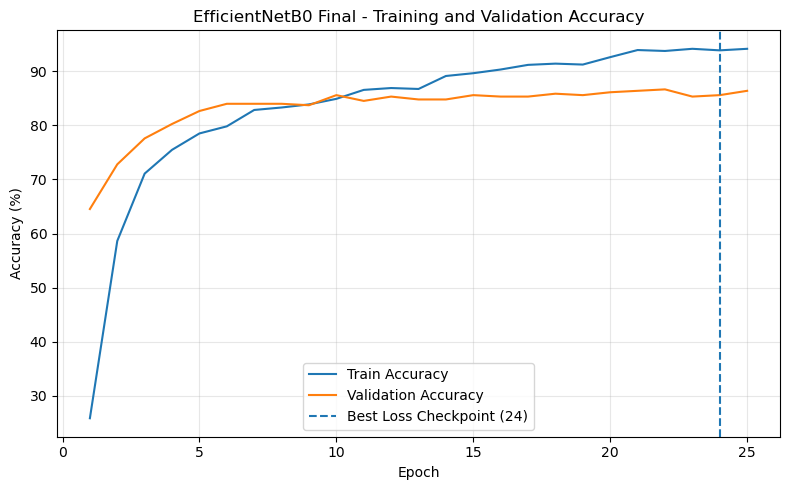

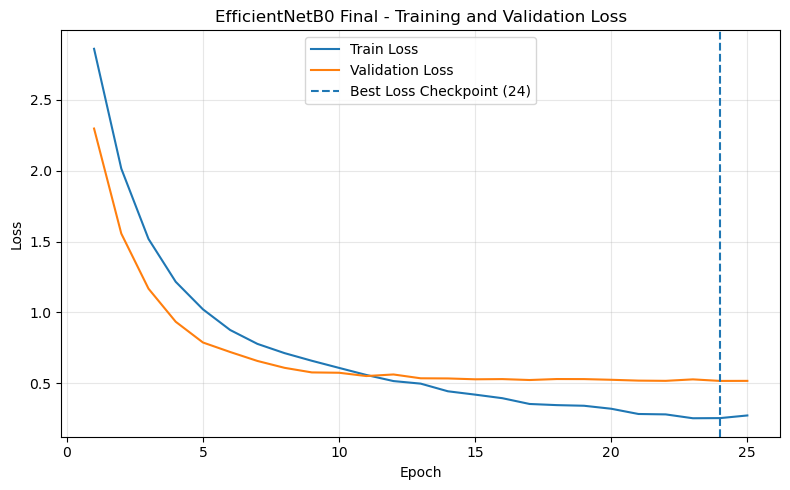

EFFICIENTNETB0 FINAL TRAINING ARTIFACTS SAVED
History : E:\SmartVision-AI\results\classification\efficientnetb0_final_history.json
Accuracy: E:\SmartVision-AI\results\classification\efficientnetb0_final_accuracy_curve.png
Loss    : E:\SmartVision-AI\results\classification\efficientnetb0_final_loss_curve.png

Checkpoint selected by validation loss:
Epoch              : 24
Validation loss    : 0.5166
Validation accuracy: 85.60%

Highest validation accuracy observed:
Epoch              : 22
Validation accuracy: 86.67%

Mixed precision    : True


In [24]:
# ============================================================
# PHASE 2 - CELL 18
# SAVE EFFICIENTNETB0 FINAL HISTORY + TRAINING CURVES
# ============================================================

import json
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(r"E:\SmartVision-AI\results\classification")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

EFFICIENT_HISTORY_PATH = (
    RESULTS_DIR / "efficientnetb0_final_history.json"
)

EFFICIENT_ACCURACY_PATH = (
    RESULTS_DIR / "efficientnetb0_final_accuracy_curve.png"
)

EFFICIENT_LOSS_PATH = (
    RESULTS_DIR / "efficientnetb0_final_loss_curve.png"
)

# ------------------------------------------------------------
# Peak validation accuracy observed
# ------------------------------------------------------------

efficient_peak_val_acc = max(
    efficient_history["val_acc"]
)

efficient_peak_val_epoch = (
    efficient_history["val_acc"].index(
        efficient_peak_val_acc
    ) + 1
)

# ------------------------------------------------------------
# Save history
# ------------------------------------------------------------

history_to_save = {
    "train_loss": [
        float(x)
        for x in efficient_history["train_loss"]
    ],

    "train_acc": [
        float(x)
        for x in efficient_history["train_acc"]
    ],

    "val_loss": [
        float(x)
        for x in efficient_history["val_loss"]
    ],

    "val_acc": [
        float(x)
        for x in efficient_history["val_acc"]
    ],

    "lr": [
        float(x)
        for x in efficient_history["lr"]
    ],

    "checkpoint_epoch":
        int(efficient_best_epoch),

    "checkpoint_val_loss":
        float(efficient_best_val_loss),

    "checkpoint_val_accuracy":
        float(efficient_best_val_acc),

    "peak_val_accuracy":
        float(efficient_peak_val_acc),

    "peak_val_accuracy_epoch":
        int(efficient_peak_val_epoch),

    "mixed_precision": bool(AMP_ENABLED)
}

with open(
    EFFICIENT_HISTORY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        history_to_save,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Accuracy curve
# ------------------------------------------------------------

epochs = range(
    1,
    len(efficient_history["train_acc"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [
        x * 100
        for x in efficient_history["train_acc"]
    ],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    [
        x * 100
        for x in efficient_history["val_acc"]
    ],
    label="Validation Accuracy"
)

plt.axvline(
    efficient_best_epoch,
    linestyle="--",
    label=(
        f"Best Loss Checkpoint "
        f"({efficient_best_epoch})"
    )
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "EfficientNetB0 Final - "
    "Training and Validation Accuracy"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    EFFICIENT_ACCURACY_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Loss curve
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    efficient_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    efficient_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    efficient_best_epoch,
    linestyle="--",
    label=(
        f"Best Loss Checkpoint "
        f"({efficient_best_epoch})"
    )
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "EfficientNetB0 Final - "
    "Training and Validation Loss"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    EFFICIENT_LOSS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("=" * 72)
print("EFFICIENTNETB0 FINAL TRAINING ARTIFACTS SAVED")
print("=" * 72)

print("History :", EFFICIENT_HISTORY_PATH)
print("Accuracy:", EFFICIENT_ACCURACY_PATH)
print("Loss    :", EFFICIENT_LOSS_PATH)

print("\nCheckpoint selected by validation loss:")
print("Epoch              :", efficient_best_epoch)

print(
    f"Validation loss    : "
    f"{efficient_best_val_loss:.4f}"
)

print(
    f"Validation accuracy: "
    f"{efficient_best_val_acc * 100:.2f}%"
)

print("\nHighest validation accuracy observed:")

print(
    "Epoch              :",
    efficient_peak_val_epoch
)

print(
    f"Validation accuracy: "
    f"{efficient_peak_val_acc * 100:.2f}%"
)

print(
    "\nMixed precision    :",
    AMP_ENABLED
)

print("=" * 72)

In [25]:
# ============================================================
# PHASE 2 - CELL 19
# LOAD ALL FINAL BEST MODEL CHECKPOINTS
# ============================================================

import torch
from pathlib import Path

MODEL_DIR = Path(r"E:\SmartVision-AI\models")

FINAL_MODEL_PATHS = {
    "VGG16":
        MODEL_DIR / "vgg16_final_best.pth",

    "ResNet50":
        MODEL_DIR / "resnet50_final_best.pth",

    "MobileNetV2":
        MODEL_DIR / "mobilenetv2_final_best.pth",

    "EfficientNetB0":
        MODEL_DIR / "efficientnetb0_final_best.pth"
}

FINAL_MODELS = {
    "VGG16": vgg16,
    "ResNet50": resnet50,
    "MobileNetV2": mobilenetv2,
    "EfficientNetB0": efficientnetb0
}

print("=" * 72)
print("LOADING FINAL BEST CLASSIFICATION CHECKPOINTS")
print("=" * 72)

loaded_checkpoint_info = {}

for model_name, model in FINAL_MODELS.items():

    checkpoint_path = FINAL_MODEL_PATHS[model_name]

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.to(device)
    model.eval()

    loaded_checkpoint_info[model_name] = {
        "epoch": checkpoint.get("epoch"),
        "val_accuracy": checkpoint.get("val_accuracy"),
        "val_loss": checkpoint.get("val_loss")
    }

    print(f"\n✅ {model_name}")
    print("   Path :", checkpoint_path)
    print("   Epoch:", checkpoint.get("epoch"))

    if checkpoint.get("val_accuracy") is not None:
        print(
            "   Val Accuracy:",
            f"{checkpoint['val_accuracy'] * 100:.2f}%"
        )

    if checkpoint.get("val_loss") is not None:
        print(
            "   Val Loss:",
            f"{checkpoint['val_loss']:.4f}"
        )

print("\n" + "=" * 72)
print("CHECKPOINT STATUS")
print("=" * 72)

for model_name, model in FINAL_MODELS.items():

    print(
        f"{model_name:15s}: "
        f"{'Evaluation mode' if not model.training else 'TRAIN MODE ERROR'}"
    )

print("\nTest images :", len(test_dataset))
print("Test batches:", len(test_loader))

print("\n" + "=" * 72)
print("✅ ALL FINAL BEST CHECKPOINTS LOADED")
print("=" * 72)

LOADING FINAL BEST CLASSIFICATION CHECKPOINTS

✅ VGG16
   Path : E:\SmartVision-AI\models\vgg16_final_best.pth
   Epoch: 11
   Val Accuracy: 84.80%

✅ ResNet50
   Path : E:\SmartVision-AI\models\resnet50_final_best.pth
   Epoch: 3
   Val Accuracy: 90.40%
   Val Loss: 0.3945

✅ MobileNetV2
   Path : E:\SmartVision-AI\models\mobilenetv2_final_best.pth
   Epoch: 14
   Val Accuracy: 81.87%

✅ EfficientNetB0
   Path : E:\SmartVision-AI\models\efficientnetb0_final_best.pth
   Epoch: 24
   Val Accuracy: 85.60%
   Val Loss: 0.5166

CHECKPOINT STATUS
VGG16          : Evaluation mode
ResNet50       : Evaluation mode
MobileNetV2    : Evaluation mode
EfficientNetB0 : Evaluation mode

Test images : 375
Test batches: 12

✅ ALL FINAL BEST CHECKPOINTS LOADED


In [26]:
# ============================================================
# PHASE 2 - CELL 20
# FINAL TEST-SET EVALUATION
# Accuracy + Precision + Recall + F1 + Top-5 Accuracy
# ============================================================

import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 72)
print("FINAL CLASSIFICATION TEST-SET EVALUATION")
print("=" * 72)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

final_test_results = []

final_predictions = {}
final_probabilities = {}
final_targets = None


# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_final_model(
    model_name,
    model,
    loader,
    device
):

    model.eval()

    all_targets = []
    all_predictions = []
    all_probabilities = []

    top5_correct = 0
    total_samples = 0

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # Forward pass
            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            # --------------------------------------------
            # Top-5 accuracy
            # --------------------------------------------

            top5_predictions = torch.topk(
                probabilities,
                k=5,
                dim=1
            ).indices

            top5_correct += (
                top5_predictions
                == labels.unsqueeze(1)
            ).any(dim=1).sum().item()

            total_samples += labels.size(0)

            # --------------------------------------------
            # Store results
            # --------------------------------------------

            all_targets.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )


    # --------------------------------------------------------
    # Convert to arrays
    # --------------------------------------------------------

    all_targets = np.array(
        all_targets
    )

    all_predictions = np.array(
        all_predictions
    )

    all_probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    precision = precision_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    top5_accuracy = (
        top5_correct / total_samples
    )


    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    final_predictions[
        model_name
    ] = all_predictions

    final_probabilities[
        model_name
    ] = all_probabilities


    # --------------------------------------------------------
    # Return metrics
    # --------------------------------------------------------

    return {
        "Model": model_name,

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1 Score (%)":
            f1 * 100,

        "Top-5 Accuracy (%)":
            top5_accuracy * 100
    }, all_targets


# ------------------------------------------------------------
# Evaluate all models
# ------------------------------------------------------------

for model_name, model in FINAL_MODELS.items():

    print(
        f"\nEvaluating {model_name}..."
    )

    metrics, targets = evaluate_final_model(
        model_name,
        model,
        test_loader,
        device
    )

    if final_targets is None:
        final_targets = targets

    final_test_results.append(
        metrics
    )

    print(
        f"✅ {model_name} complete"
    )


# ------------------------------------------------------------
# Results dataframe
# ------------------------------------------------------------

final_results_df = pd.DataFrame(
    final_test_results
)

final_results_df = final_results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("FINAL TEST RESULTS")
print("=" * 72)

print(
    final_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

print("\nEvaluation samples :", len(final_targets))
print("Number of classes  :", len(test_dataset.classes))
print("Samples per class  : 15")

print("\nMetric averaging:")
print("Precision / Recall / F1 : Macro")

print("\n" + "=" * 72)
print("✅ FINAL TEST-SET EVALUATION COMPLETE")
print("=" * 72)

FINAL CLASSIFICATION TEST-SET EVALUATION

Evaluating VGG16...
✅ VGG16 complete

Evaluating ResNet50...
✅ ResNet50 complete

Evaluating MobileNetV2...
✅ MobileNetV2 complete

Evaluating EfficientNetB0...
✅ EfficientNetB0 complete

FINAL TEST RESULTS
         Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  Top-5 Accuracy (%)
      ResNet50         86.13          88.19       86.13         86.27               97.07
EfficientNetB0         84.27          85.65       84.27         84.16               97.60
         VGG16         81.60          83.12       81.60         81.39               97.87
   MobileNetV2         79.73          81.48       79.73         79.69               95.47

Evaluation samples : 375
Number of classes  : 25
Samples per class  : 15

Metric averaging:
Precision / Recall / F1 : Macro

✅ FINAL TEST-SET EVALUATION COMPLETE


In [27]:
# ============================================================
# PHASE 2 - CELL 21
# INFERENCE SPEED + MODEL SIZE COMPARISON
# ============================================================

import time
import torch
import pandas as pd

print("=" * 72)
print("FINAL MODEL EFFICIENCY COMPARISON")
print("=" * 72)

efficiency_results = []

# ------------------------------------------------------------
# Use one real test image for batch-size-1 latency
# ------------------------------------------------------------

sample_image, _ = test_dataset[0]

sample_image = (
    sample_image
    .unsqueeze(0)
    .to(device)
)

# ------------------------------------------------------------
# Measure every model
# ------------------------------------------------------------

for model_name, model in FINAL_MODELS.items():

    print(f"\nMeasuring {model_name}...")

    model.eval()

    # --------------------------------------------------------
    # Model parameter size
    # --------------------------------------------------------

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
    )

    model_size_bytes = sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    )

    model_size_mb = (
        model_size_bytes / (1024 ** 2)
    )

    # --------------------------------------------------------
    # GPU warm-up
    # --------------------------------------------------------

    with torch.inference_mode():

        for _ in range(20):
            _ = model(sample_image)

    if device.type == "cuda":
        torch.cuda.synchronize()

    # --------------------------------------------------------
    # Batch-size-1 inference timing
    # --------------------------------------------------------

    timings = []

    with torch.inference_mode():

        for _ in range(100):

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            _ = model(sample_image)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end = time.perf_counter()

            timings.append(
                (end - start) * 1000
            )

    average_latency = sum(timings) / len(timings)

    sorted_timings = sorted(timings)

    median_latency = sorted_timings[
        len(sorted_timings) // 2
    ]

    fps = 1000 / average_latency

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    efficiency_results.append({
        "Model": model_name,
        "Parameters (M)":
            parameter_count / 1_000_000,
        "Model Size (MB)":
            model_size_mb,
        "Avg Inference (ms)":
            average_latency,
        "Median Inference (ms)":
            median_latency,
        "FPS":
            fps
    })

    print(
        f"✅ {model_name}: "
        f"{average_latency:.2f} ms/image | "
        f"{fps:.2f} FPS | "
        f"{model_size_mb:.2f} MB"
    )

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

efficiency_df = pd.DataFrame(
    efficiency_results
)

efficiency_df = efficiency_df.sort_values(
    by="Avg Inference (ms)"
).reset_index(drop=True)

print("\n" + "=" * 72)
print("INFERENCE SPEED AND MODEL SIZE")
print("=" * 72)

print(
    efficiency_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

print("\nTiming conditions:")
print("Device       :", device)
print("Batch size   : 1")
print("Warm-up runs : 20")
print("Timed runs   : 100")

print("\nModel size:")
print("Calculated from model parameters only")
print("(optimizer/checkpoint data excluded)")

print("\n" + "=" * 72)
print("✅ EFFICIENCY EVALUATION COMPLETE")
print("=" * 72)

FINAL MODEL EFFICIENCY COMPARISON

Measuring VGG16...
✅ VGG16: 4.97 ms/image | 201.17 FPS | 155.16 MB

Measuring ResNet50...
✅ ResNet50: 11.27 ms/image | 88.73 FPS | 93.73 MB

Measuring MobileNetV2...
✅ MobileNetV2: 10.45 ms/image | 95.73 FPS | 11.03 MB

Measuring EfficientNetB0...
✅ EfficientNetB0: 15.25 ms/image | 65.56 FPS | 17.84 MB

INFERENCE SPEED AND MODEL SIZE
         Model  Parameters (M)  Model Size (MB)  Avg Inference (ms)  Median Inference (ms)    FPS
         VGG16           40.67           155.16                4.97                   4.91 201.17
   MobileNetV2            2.89            11.03               10.45                  11.36  95.73
      ResNet50           24.57            93.73               11.27                  10.35  88.73
EfficientNetB0            4.68            17.84               15.25                  16.08  65.56

Timing conditions:
Device       : cuda
Batch size   : 1
Warm-up runs : 20
Timed runs   : 100

Model size:
Calculated from model parameters

GENERATING FINAL CONFUSION MATRICES


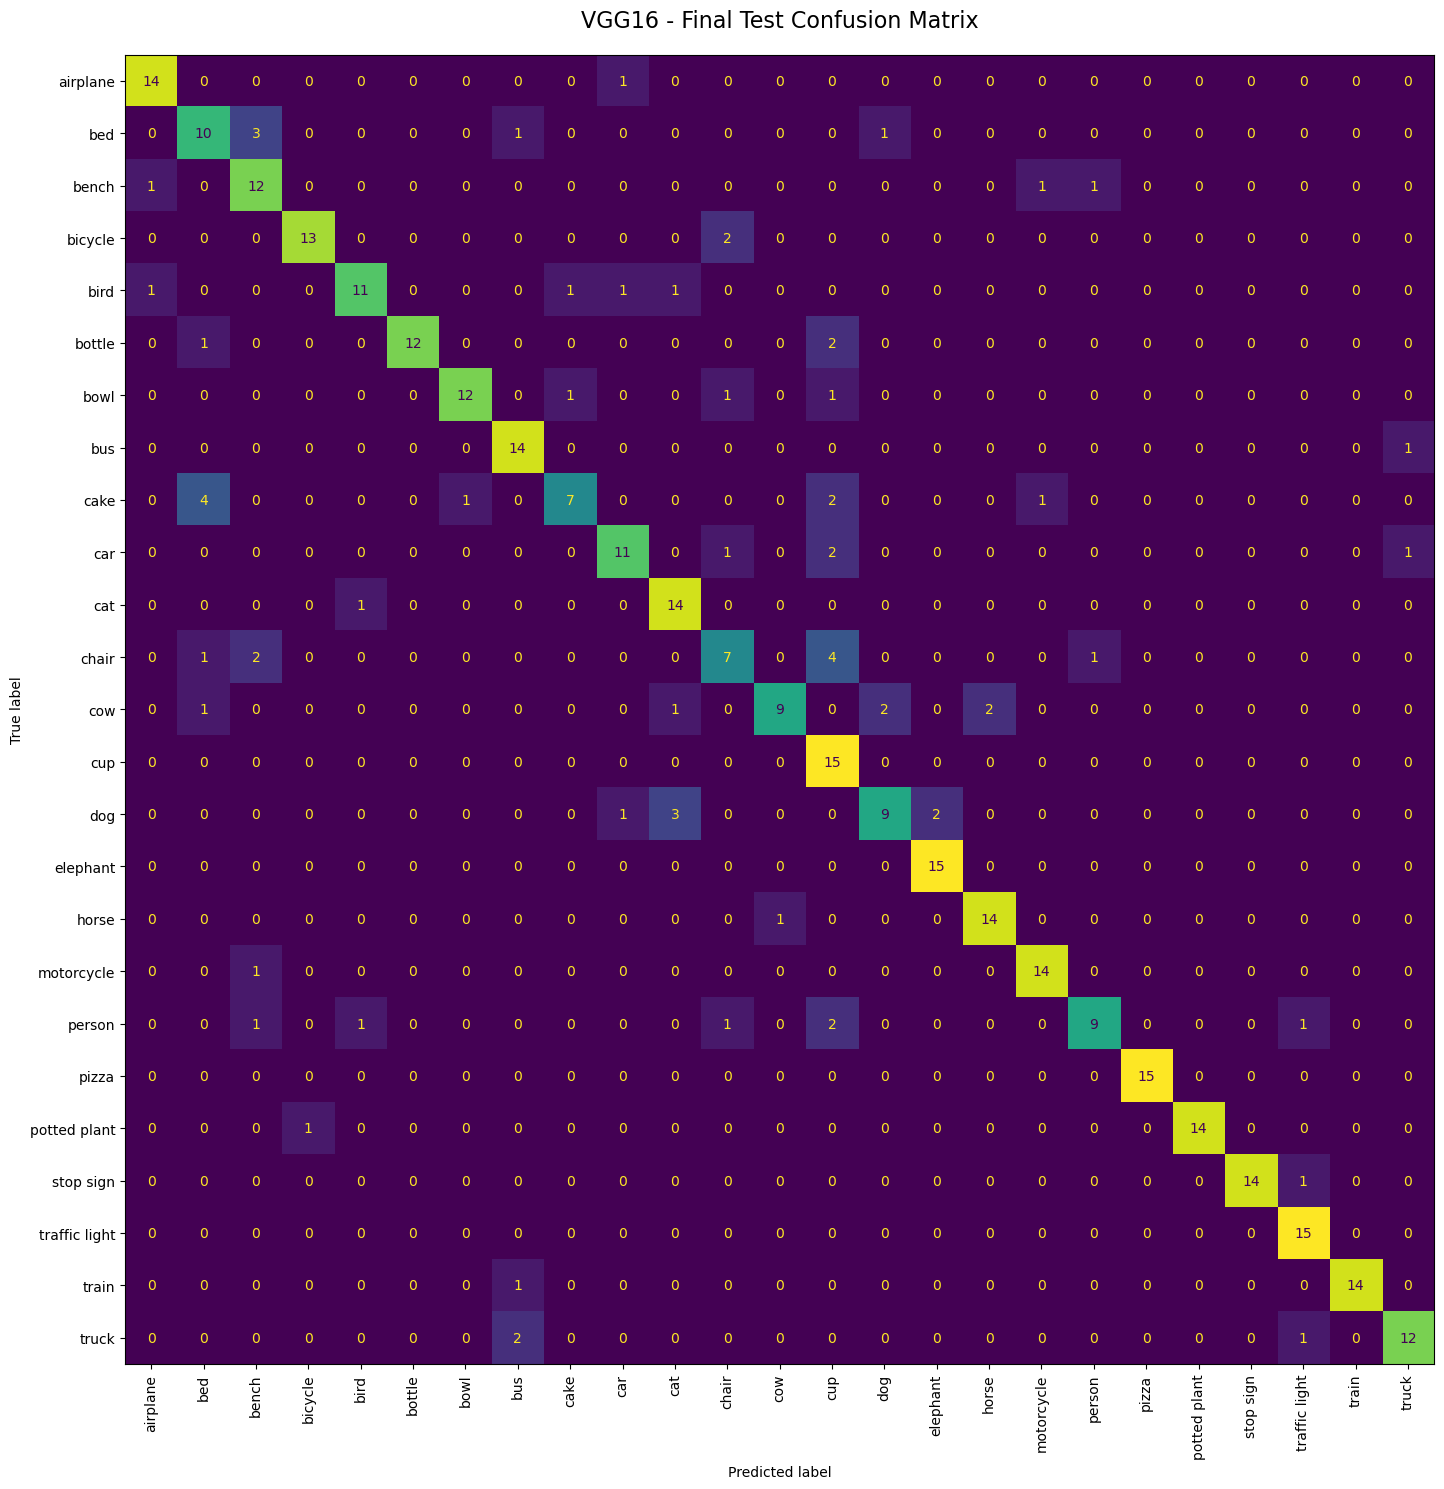


✅ VGG16
   Correct   : 306/375
   Incorrect : 69/375
   Saved     : E:\SmartVision-AI\results\classification\vgg16_final_confusion_matrix.png


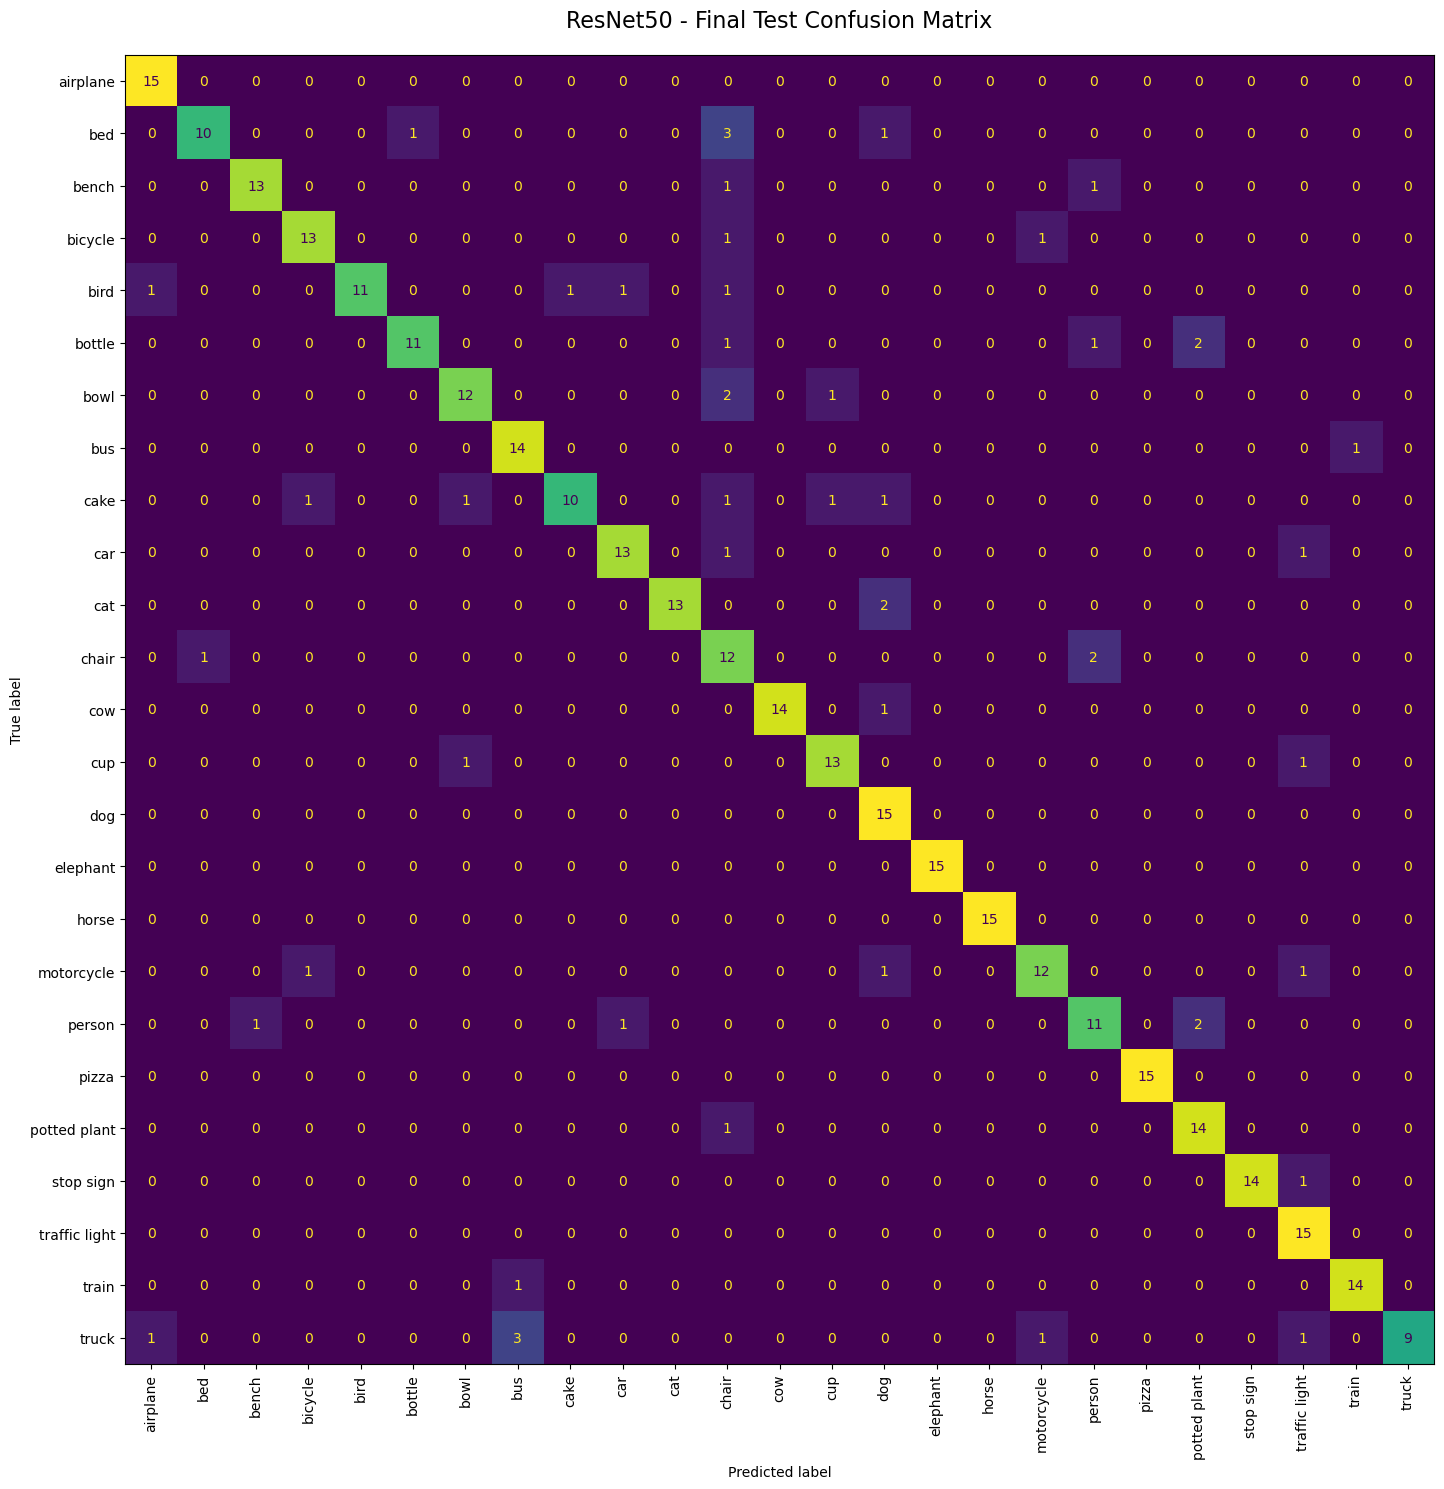


✅ ResNet50
   Correct   : 323/375
   Incorrect : 52/375
   Saved     : E:\SmartVision-AI\results\classification\resnet50_final_confusion_matrix.png


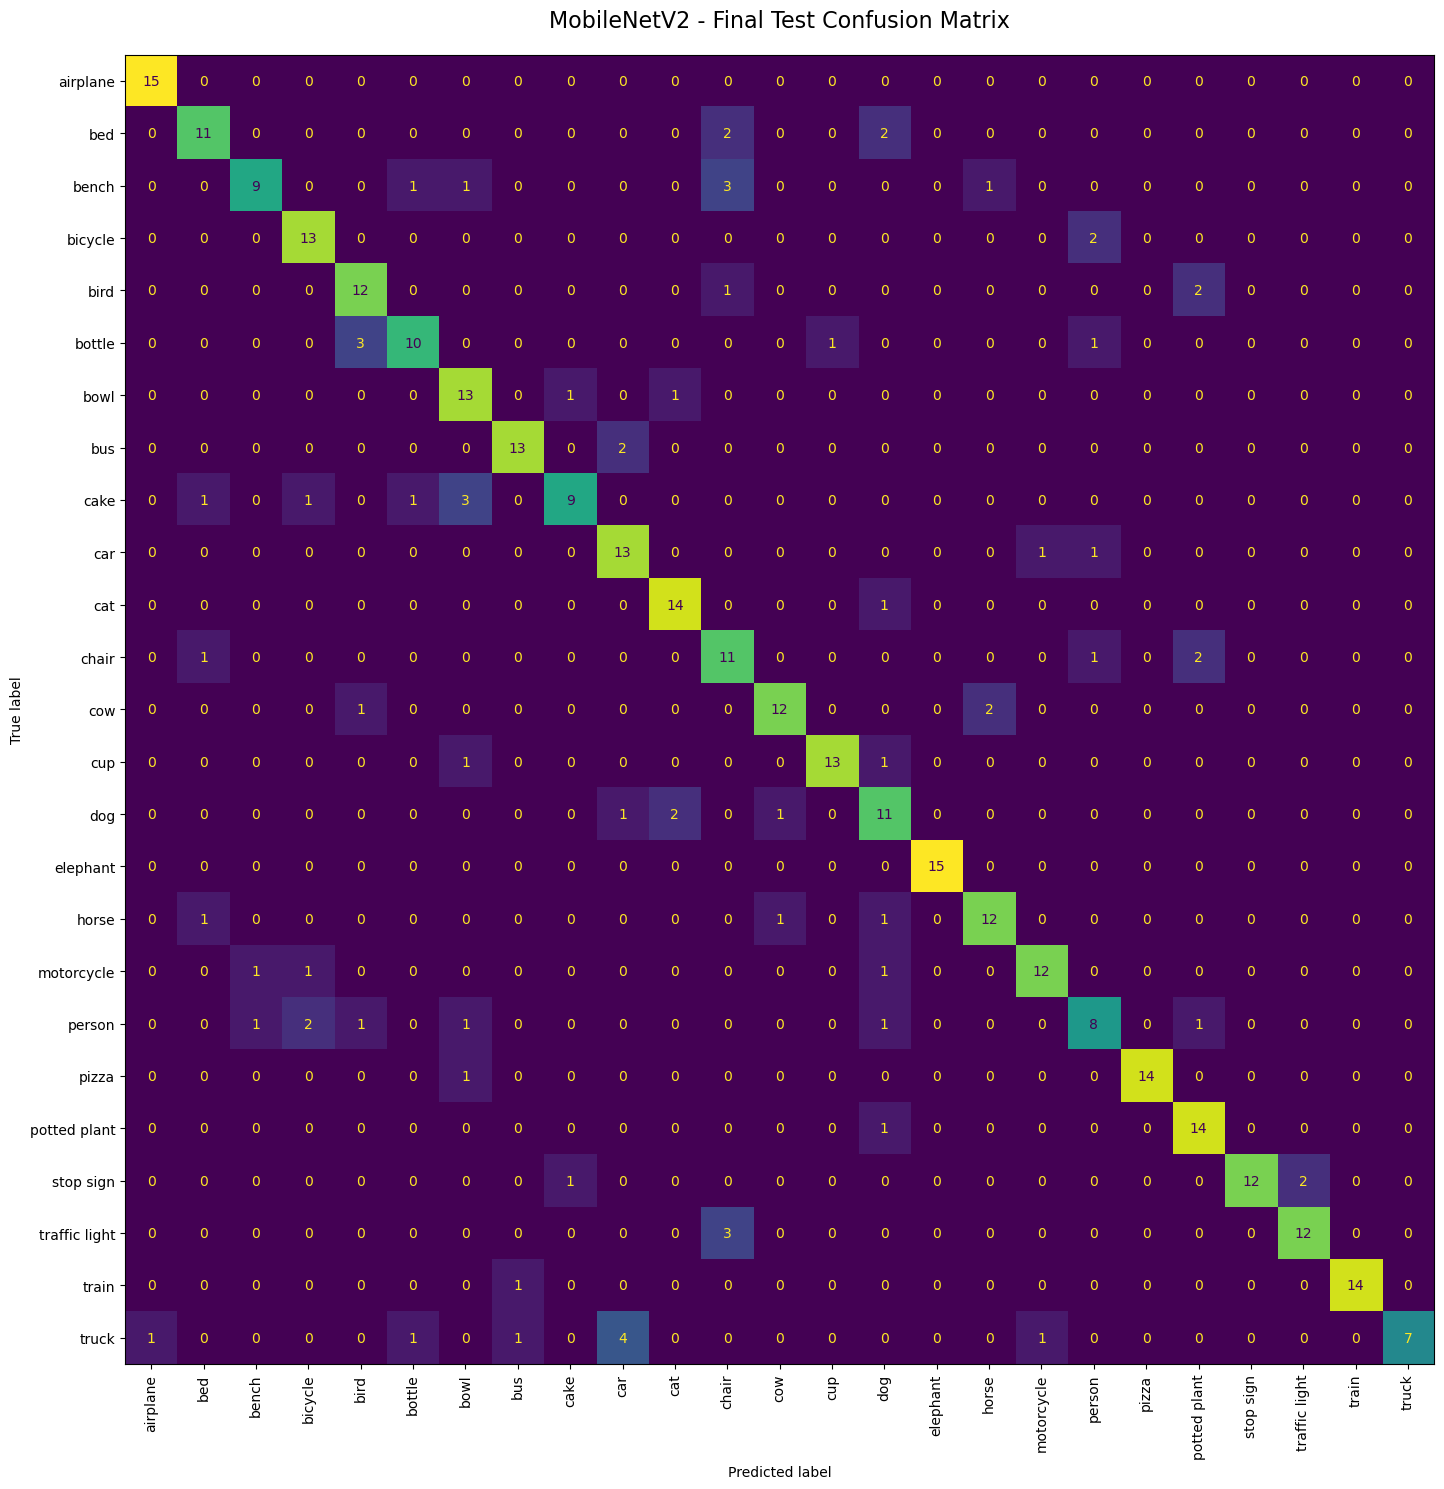


✅ MobileNetV2
   Correct   : 299/375
   Incorrect : 76/375
   Saved     : E:\SmartVision-AI\results\classification\mobilenetv2_final_confusion_matrix.png


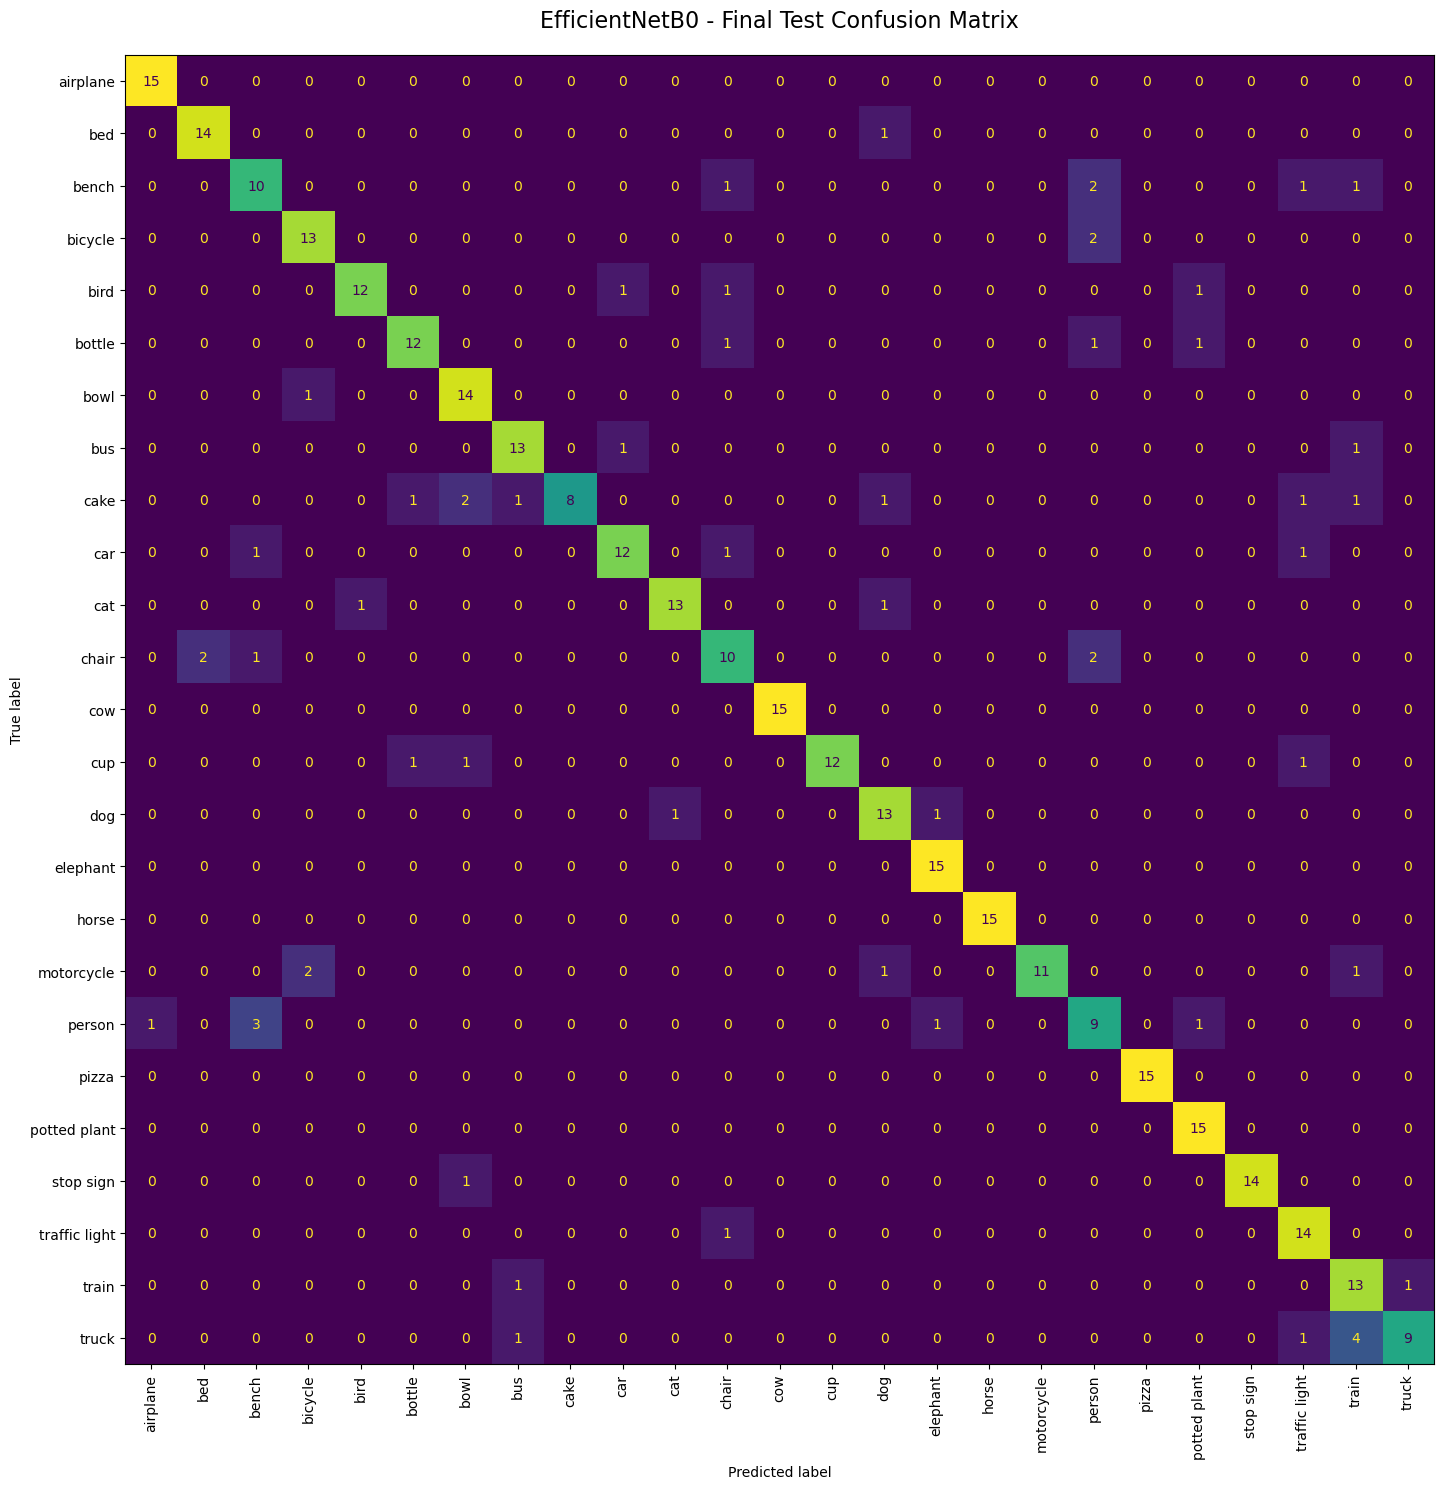


✅ EfficientNetB0
   Correct   : 316/375
   Incorrect : 59/375
   Saved     : E:\SmartVision-AI\results\classification\efficientnetb0_final_confusion_matrix.png

CONFUSION MATRIX SUMMARY
VGG16          : 306/375 correct (81.60%)
ResNet50       : 323/375 correct (86.13%)
MobileNetV2    : 299/375 correct (79.73%)
EfficientNetB0 : 316/375 correct (84.27%)

✅ ALL FINAL CONFUSION MATRICES SAVED


In [28]:
# ============================================================
# PHASE 2 - CELL 22
# FINAL CONFUSION MATRICES - ALL 4 MODELS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\classification"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

class_names = test_dataset.classes

confusion_matrices = {}

print("=" * 72)
print("GENERATING FINAL CONFUSION MATRICES")
print("=" * 72)

for model_name in FINAL_MODELS.keys():

    # --------------------------------------------------------
    # Calculate confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        final_targets,
        final_predictions[model_name]
    )

    confusion_matrices[model_name] = cm

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(15, 15)
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display.plot(
        ax=ax,
        xticks_rotation=90,
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"{model_name} - Final Test Confusion Matrix",
        fontsize=16,
        pad=20
    )

    plt.tight_layout()

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    filename = (
        RESULTS_DIR /
        f"{model_name.lower()}_final_confusion_matrix.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # --------------------------------------------------------
    # Correct / incorrect summary
    # --------------------------------------------------------

    correct = np.trace(cm)

    total = cm.sum()

    incorrect = total - correct

    print(f"\n✅ {model_name}")
    print(f"   Correct   : {correct}/{total}")
    print(f"   Incorrect : {incorrect}/{total}")
    print(f"   Saved     : {filename}")


print("\n" + "=" * 72)
print("CONFUSION MATRIX SUMMARY")
print("=" * 72)

for model_name, cm in confusion_matrices.items():

    correct = np.trace(cm)
    total = cm.sum()

    print(
        f"{model_name:15s}: "
        f"{correct:3d}/{total} correct "
        f"({correct/total*100:.2f}%)"
    )

print("\n" + "=" * 72)
print("✅ ALL FINAL CONFUSION MATRICES SAVED")
print("=" * 72)

FINAL CLASSIFICATION MODEL COMPARISON
         Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  Top-5 Accuracy (%)  Parameters (M)  Model Size (MB)  Avg Inference (ms)  Median Inference (ms)    FPS
      ResNet50         86.13          88.19       86.13         86.27               97.07           24.57            93.73               11.27                  10.35  88.73
EfficientNetB0         84.27          85.65       84.27         84.16               97.60            4.68            17.84               15.25                  16.08  65.56
         VGG16         81.60          83.12       81.60         81.39               97.87           40.67           155.16                4.97                   4.91 201.17
   MobileNetV2         79.73          81.48       79.73         79.69               95.47            2.89            11.03               10.45                  11.36  95.73


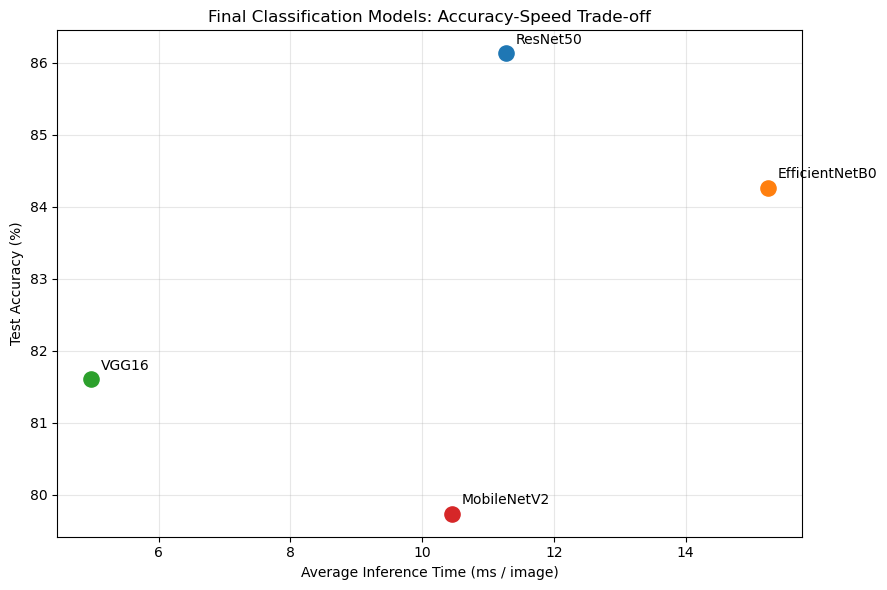

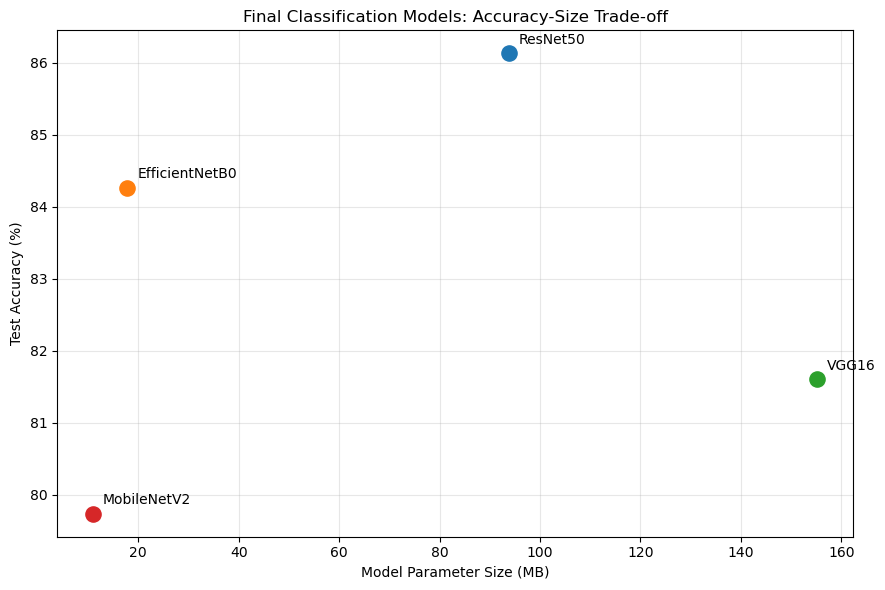


FINAL COMPARISON HIGHLIGHTS
Highest Test Accuracy : ResNet50 (86.13%)
Highest Macro F1      : ResNet50 (86.27%)
Highest Top-5 Accuracy: VGG16 (97.87%)
Fastest Inference     : VGG16 (4.97 ms/image)
Smallest Model        : MobileNetV2 (11.03 MB)

Saved:
E:\SmartVision-AI\results\classification\final_model_comparison.csv
E:\SmartVision-AI\results\classification\final_accuracy_speed_tradeoff.png
E:\SmartVision-AI\results\classification\final_accuracy_size_tradeoff.png

✅ FINAL MODEL COMPARISON ARTIFACTS SAVED


In [29]:
# ============================================================
# PHASE 2 - CELL 23
# FINAL MODEL COMPARISON
# COMBINED TABLE + ACCURACY-SPEED TRADE-OFF
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\classification"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Combine predictive + efficiency results
# ------------------------------------------------------------

final_comparison_df = pd.merge(
    final_results_df,
    efficiency_df,
    on="Model",
    how="inner"
)

# Arrange columns
final_comparison_df = final_comparison_df[
    [
        "Model",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1 Score (%)",
        "Top-5 Accuracy (%)",
        "Parameters (M)",
        "Model Size (MB)",
        "Avg Inference (ms)",
        "Median Inference (ms)",
        "FPS"
    ]
]

# Sort by final test accuracy
final_comparison_df = (
    final_comparison_df
    .sort_values(
        by="Accuracy (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Save final comparison CSV
# ------------------------------------------------------------

COMPARISON_CSV = (
    RESULTS_DIR /
    "final_model_comparison.csv"
)

final_comparison_df.to_csv(
    COMPARISON_CSV,
    index=False
)

# ------------------------------------------------------------
# Display table
# ------------------------------------------------------------

print("=" * 100)
print("FINAL CLASSIFICATION MODEL COMPARISON")
print("=" * 100)

print(
    final_comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ------------------------------------------------------------
# Accuracy vs inference latency
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for _, row in final_comparison_df.iterrows():

    plt.scatter(
        row["Avg Inference (ms)"],
        row["Accuracy (%)"],
        s=120
    )

    plt.annotate(
        row["Model"],
        (
            row["Avg Inference (ms)"],
            row["Accuracy (%)"]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10
    )

plt.xlabel(
    "Average Inference Time (ms / image)"
)

plt.ylabel(
    "Test Accuracy (%)"
)

plt.title(
    "Final Classification Models: "
    "Accuracy-Speed Trade-off"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

ACCURACY_SPEED_PATH = (
    RESULTS_DIR /
    "final_accuracy_speed_tradeoff.png"
)

plt.savefig(
    ACCURACY_SPEED_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Accuracy vs model size
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for _, row in final_comparison_df.iterrows():

    plt.scatter(
        row["Model Size (MB)"],
        row["Accuracy (%)"],
        s=120
    )

    plt.annotate(
        row["Model"],
        (
            row["Model Size (MB)"],
            row["Accuracy (%)"]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10
    )

plt.xlabel(
    "Model Parameter Size (MB)"
)

plt.ylabel(
    "Test Accuracy (%)"
)

plt.title(
    "Final Classification Models: "
    "Accuracy-Size Trade-off"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

ACCURACY_SIZE_PATH = (
    RESULTS_DIR /
    "final_accuracy_size_tradeoff.png"
)

plt.savefig(
    ACCURACY_SIZE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Useful factual comparisons
# ------------------------------------------------------------

best_accuracy_row = final_comparison_df.loc[
    final_comparison_df["Accuracy (%)"].idxmax()
]

fastest_row = final_comparison_df.loc[
    final_comparison_df["Avg Inference (ms)"].idxmin()
]

smallest_row = final_comparison_df.loc[
    final_comparison_df["Model Size (MB)"].idxmin()
]

best_f1_row = final_comparison_df.loc[
    final_comparison_df["F1 Score (%)"].idxmax()
]

best_top5_row = final_comparison_df.loc[
    final_comparison_df["Top-5 Accuracy (%)"].idxmax()
]

print("\n" + "=" * 100)
print("FINAL COMPARISON HIGHLIGHTS")
print("=" * 100)

print(
    f"Highest Test Accuracy : "
    f"{best_accuracy_row['Model']} "
    f"({best_accuracy_row['Accuracy (%)']:.2f}%)"
)

print(
    f"Highest Macro F1      : "
    f"{best_f1_row['Model']} "
    f"({best_f1_row['F1 Score (%)']:.2f}%)"
)

print(
    f"Highest Top-5 Accuracy: "
    f"{best_top5_row['Model']} "
    f"({best_top5_row['Top-5 Accuracy (%)']:.2f}%)"
)

print(
    f"Fastest Inference     : "
    f"{fastest_row['Model']} "
    f"({fastest_row['Avg Inference (ms)']:.2f} ms/image)"
)

print(
    f"Smallest Model        : "
    f"{smallest_row['Model']} "
    f"({smallest_row['Model Size (MB)']:.2f} MB)"
)

print("\nSaved:")
print(COMPARISON_CSV)
print(ACCURACY_SPEED_PATH)
print(ACCURACY_SIZE_PATH)

print("\n" + "=" * 100)
print("✅ FINAL MODEL COMPARISON ARTIFACTS SAVED")
print("=" * 100)

In [30]:
# ============================================================
# PHASE 2 - CELL 24
# FINAL CLASSIFICATION MODEL SELECTION
# ============================================================

import json
from pathlib import Path

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\classification"
)

SELECTION_PATH = (
    RESULTS_DIR /
    "final_classification_model_selection.json"
)

# ------------------------------------------------------------
# Selected model
# ------------------------------------------------------------

SELECTED_CLASSIFICATION_MODEL = "ResNet50"

selected_row = final_comparison_df[
    final_comparison_df["Model"]
    == SELECTED_CLASSIFICATION_MODEL
].iloc[0]

selection_summary = {

    "selected_model":
        SELECTED_CLASSIFICATION_MODEL,

    "checkpoint":
        str(
            FINAL_MODEL_PATHS[
                SELECTED_CLASSIFICATION_MODEL
            ]
        ),

    "test_accuracy_percent":
        float(selected_row["Accuracy (%)"]),

    "precision_macro_percent":
        float(selected_row["Precision (%)"]),

    "recall_macro_percent":
        float(selected_row["Recall (%)"]),

    "f1_macro_percent":
        float(selected_row["F1 Score (%)"]),

    "top5_accuracy_percent":
        float(selected_row["Top-5 Accuracy (%)"]),

    "parameters_million":
        float(selected_row["Parameters (M)"]),

    "parameter_size_mb":
        float(selected_row["Model Size (MB)"]),

    "average_inference_ms":
        float(selected_row["Avg Inference (ms)"]),

    "fps":
        float(selected_row["FPS"]),

    "selection_reason":
        (
            "Selected for the final classification pipeline "
            "because it achieved the highest test accuracy "
            "and highest macro F1 score among the four final "
            "classification models while maintaining practical "
            "GPU inference speed."
        ),

    "comparison_notes": {

        "VGG16":
            "Fastest measured batch-size-1 GPU inference, "
            "but lower classification accuracy and largest model.",

        "MobileNetV2":
            "Smallest model, but lowest test accuracy.",

        "EfficientNetB0":
            "Compact model with strong accuracy, but slower "
            "measured batch-size-1 GPU inference.",

        "ResNet50":
            "Highest test accuracy and macro F1 with practical "
            "inference performance."
    }
}

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

with open(
    SELECTION_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selection_summary,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 78)
print("FINAL CLASSIFICATION MODEL SELECTED")
print("=" * 78)

print(
    "Selected Model       :",
    SELECTED_CLASSIFICATION_MODEL
)

print(
    f"Test Accuracy        : "
    f"{selected_row['Accuracy (%)']:.2f}%"
)

print(
    f"Macro Precision      : "
    f"{selected_row['Precision (%)']:.2f}%"
)

print(
    f"Macro Recall         : "
    f"{selected_row['Recall (%)']:.2f}%"
)

print(
    f"Macro F1             : "
    f"{selected_row['F1 Score (%)']:.2f}%"
)

print(
    f"Top-5 Accuracy       : "
    f"{selected_row['Top-5 Accuracy (%)']:.2f}%"
)

print(
    f"Inference Time       : "
    f"{selected_row['Avg Inference (ms)']:.2f} ms/image"
)

print(
    f"FPS                  : "
    f"{selected_row['FPS']:.2f}"
)

print(
    f"Model Size           : "
    f"{selected_row['Model Size (MB)']:.2f} MB"
)

print("\nFinal checkpoint:")
print(
    FINAL_MODEL_PATHS[
        SELECTED_CLASSIFICATION_MODEL
    ]
)

print("\nSelection record:")
print(SELECTION_PATH)

print("\nReason:")
print(
    selection_summary["selection_reason"]
)

print("\n" + "=" * 78)
print("✅ PHASE 2 - CLASSIFICATION COMPLETE")
print("=" * 78)

FINAL CLASSIFICATION MODEL SELECTED
Selected Model       : ResNet50
Test Accuracy        : 86.13%
Macro Precision      : 88.19%
Macro Recall         : 86.13%
Macro F1             : 86.27%
Top-5 Accuracy       : 97.07%
Inference Time       : 11.27 ms/image
FPS                  : 88.73
Model Size           : 93.73 MB

Final checkpoint:
E:\SmartVision-AI\models\resnet50_final_best.pth

Selection record:
E:\SmartVision-AI\results\classification\final_classification_model_selection.json

Reason:
Selected for the final classification pipeline because it achieved the highest test accuracy and highest macro F1 score among the four final classification models while maintaining practical GPU inference speed.

✅ PHASE 2 - CLASSIFICATION COMPLETE
